# FFOR multi-timestep ? grid 20_0

Notebook per calcolare una **FFOR multi-timestep sostenuta** della rete `20_0`, seguendo la formulazione del paper: QuickFlex costruisce la frontiera esterna, ma ogni valutazione direzionale risolve un unico OPF sull'intero orizzonte.

## Differenze rispetto al single-step FFOR

1. **Variabili indicizzate per timestep**: ogni dispositivo e ogni vincolo OPF istantaneo sono replicati per `t = 0, ..., N_TIMESTEPS - 1`.
2. **Flessibilita PCC comune**: la deviazione rispetto alla baseline variabile nel tempo e' rappresentata da due variabili comuni, `P_flex_common_pu` e `Q_flex_common_pu`.
3. **Vincoli intertemporali**:
   - SoC BESS con una variabile attiva firmata e efficienza approssimata al 100%;
   - temperatura indoor HP con modello termico lineare basato su capacita, conducibilita, COP e temperatura esterna.
4. **Baseline variabile nel tempo**: demand, PV, HP ed EV cambiano a ogni timestep. Le EV sono incluse solo come carico fisso.
5. **QuickFlex invariato come algoritmo esterno**: ogni direzione QuickFlex chiama `solve_direction(alpha, beta)`, che risolve l'OPF multi-timestep.

This implementation computes a sustained multi-timestep FFOR. Each boundary point represents a constant active/reactive PCC flexibility deviation that can be maintained over the selected horizon. QuickFlex is used as the outer boundary-construction algorithm, while each directional optimization is a multi-timestep OPF with BESS SOC and HP thermal dynamics. EVs are included only as fixed baseline loads.

In [ ]:
import json
import math
import os
from pathlib import Path
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
from types import SimpleNamespace


GRID_NAME = os.getenv("FFOR_GRID_NAME", "20_0")
DATA_YEAR = int(os.getenv("FFOR_DATA_YEAR", "2050"))
TARGET_TIME = os.getenv("FFOR_TARGET_TIME", "12-15 20:00:00")
START_TIMESTAMP = TARGET_TIME

# === MULTI-TIMESTEP PARAMETERS ===
# The paper writes t = 0, ..., d. In code we use exactly N_TIMESTEPS intervals:
# t = 0, ..., N_TIMESTEPS - 1, with state variables also available at t = N_TIMESTEPS.
N_TIMESTEPS = int(os.getenv("FFOR_N_TIMESTEPS", os.getenv("FFOR_D", "1")))
DT_H = float(os.getenv("FFOR_DT_H", "1.0"))  # Hours per timestep (1.0 = hourly profiles)

SBASE_MVA = 100.0
SBASE_KW = SBASE_MVA * 1000.0
SBASE_KVAR = SBASE_MVA * 1000.0

PF_DER = 0.95
TAN_PHI = math.tan(math.acos(PF_DER))

# Existing notebook values are kept as defaults, but exposed with clearer names.
SOC_INITIAL = float(os.getenv("FFOR_SOC_INITIAL", "0.60"))
SOC_INIT = SOC_INITIAL  # Backward-compatible alias used in older diagnostic text.
SOC_MIN = float(os.getenv("FFOR_SOC_MIN", "0.40"))
SOC_MAX = float(os.getenv("FFOR_SOC_MAX", "0.80"))
ENFORCE_FINAL_SOC = os.getenv("FFOR_ENFORCE_FINAL_SOC", "0").lower() in {"1", "true", "yes"}
SOC_FINAL_TOL = float(os.getenv("FFOR_SOC_FINAL_TOL", "0.02"))

T_SET_C = float(os.getenv("FFOR_T_SET_C", "20.0"))
T_BAND_C = float(os.getenv("FFOR_T_BAND_C", "1.0"))
T_MIN_C = T_SET_C - T_BAND_C
T_MAX_C = T_SET_C + T_BAND_C
ENFORCE_FINAL_TEMPERATURE = os.getenv("FFOR_ENFORCE_FINAL_TEMPERATURE", "0").lower() in {"1", "true", "yes"}
T_FINAL_TOL = float(os.getenv("FFOR_T_FINAL_TOL", "0.25"))

HP_POWER_MARGIN_FACTOR = float(os.getenv("FFOR_HP_POWER_MARGIN_FACTOR", "0.9"))
if HP_POWER_MARGIN_FACTOR <= 0.0:
    raise ValueError("HP_POWER_MARGIN_FACTOR must be positive")

N_POLY = 16
INNER_POLY_RADIUS = math.cos(math.pi / N_POLY)
FFOR_EPSILON = 1e-10

TOL_LINE_BINDING = 1e-3
TOL_VOLT_BINDING = 1e-3
TOL_LINE_NEAR = 0.03
TOL_VOLT_NEAR = 0.01
TOL_DER = 1e-5

OUTPUT_DIR = Path("outputs") / (
    f"ffor_multistep_{GRID_NAME}_{DATA_YEAR}_"
    f"{TARGET_TIME.replace(' ', '_').replace(':', '-')}_N{N_TIMESTEPS}_dt{DT_H}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

print(f"Multi-timestep FFOR: grid={GRID_NAME}, year={DATA_YEAR}")
print(f"Start timestamp: {START_TIMESTAMP}")
print(f"N_TIMESTEPS={N_TIMESTEPS}, DT_H={DT_H}h, horizon={N_TIMESTEPS * DT_H}h")
print(f"Output dir: {OUTPUT_DIR}")

Multi-timestep FFOR: grid=20_0, year=2050
Start timestamp: 12-15 20:00:00
N_TIMESTEPS=1, DT_H=1.0h, horizon=1.0h
Output dir: outputs\ffor_multistep_20_0_2050_12-15_20-00-00_N1_dt1.0


## 1. Costruzione della lista timestep

`N_TIMESTEPS` e' il numero di intervalli/timestep considerati nel modello. Se il paper usa `t = 0, ..., d`, qui il codice usa `t = 0, ..., N_TIMESTEPS - 1`; le variabili di stato intertemporali sono definite anche all'estremo finale `t = N_TIMESTEPS`.

I profili del loader sono orari, quindi il caso standard usa `DT_H = 1.0`.

In [2]:
PROFILE_DIR = Path("outputs") / f"{GRID_NAME}_profiles_mveq_evbase_{DATA_YEAR}"
FFOR_INPUT_DIR = PROFILE_DIR / "ffor_inputs"

time_columns_df = pd.read_csv(FFOR_INPUT_DIR / "time_columns.csv")
available_times = time_columns_df["time_column"].astype(str).tolist()

if TARGET_TIME not in available_times:
    raise ValueError(f"TARGET_TIME {TARGET_TIME} not in available time columns")

start_idx = available_times.index(TARGET_TIME)
if start_idx + N_TIMESTEPS > len(available_times):
    raise ValueError(
        f"Not enough timesteps after {TARGET_TIME}: need {N_TIMESTEPS}, "
        f"have {len(available_times) - start_idx}"
    )

TIMESTEPS = available_times[start_idx : start_idx + N_TIMESTEPS]

print(f"Horizon timesteps ({N_TIMESTEPS}):")
for t, ts in enumerate(TIMESTEPS):
    print(f"  t={t}: {ts}")

Horizon timesteps (1):
  t=0: 12-15 20:00:00


## 2. Caricamento rete e dati pre-cached

Usa la cache `_evbase_` prodotta da `loader_definitivo.py` con `PierpolloGrid20EVBaseLoader`. La cache include la baseline EV come carico fisso (no V1G flexibility in questo modello).

In [3]:
# Load only pre-computed cached inputs from outputs/, as in the single-step notebook.
required_cached_files = [
    PROFILE_DIR / "baseline_demand_by_mv_node.csv",
    PROFILE_DIR / "hp_baseline_by_mv_node.csv",
    PROFILE_DIR / "pv_generation_by_mv_node.csv",
    PROFILE_DIR / "ev_baseline_by_mv_node.csv",
    PROFILE_DIR / "ev_baseline_q_by_mv_node.csv",
    PROFILE_DIR / "bess_allocation_mveq.csv",
    FFOR_INPUT_DIR / "nodes.csv",
    FFOR_INPUT_DIR / "pv_mv_generation.csv",
    FFOR_INPUT_DIR / "pv_lv_generation.csv",
    FFOR_INPUT_DIR / "hp_mv_allocation.csv",
    FFOR_INPUT_DIR / "hp_lv_allocation.csv",
    FFOR_INPUT_DIR / "temperature_profiles.csv",
    FFOR_INPUT_DIR / "time_columns.csv",
]
missing_cached_files = [path for path in required_cached_files if not path.exists()]
if missing_cached_files:
    missing_list = "\n".join(f"- {path}" for path in missing_cached_files)
    raise FileNotFoundError(f"Missing precomputed files in outputs/:\n{missing_list}")

nodes = pd.read_csv(FFOR_INPUT_DIR / "nodes.csv", dtype={"osmid": str, "lv_grid": str})
baseline_demand_by_mv_node = pd.read_csv(PROFILE_DIR / "baseline_demand_by_mv_node.csv")
hp_baseline_by_mv_node = pd.read_csv(PROFILE_DIR / "hp_baseline_by_mv_node.csv")
pv_generation_by_mv_node = pd.read_csv(PROFILE_DIR / "pv_generation_by_mv_node.csv")
ev_baseline_by_mv_node = pd.read_csv(PROFILE_DIR / "ev_baseline_by_mv_node.csv")
ev_baseline_q_by_mv_node = pd.read_csv(PROFILE_DIR / "ev_baseline_q_by_mv_node.csv")
bess_allocation = pd.read_csv(PROFILE_DIR / "bess_allocation_mveq.csv")

mv_nodes_with_lv = nodes[nodes["lv_grid"].astype(str).ne("-1")].copy()
mv_to_lv = dict(zip(mv_nodes_with_lv["osmid"].astype(str), mv_nodes_with_lv["lv_grid"].astype(str)))
lv_to_mv = {lv_grid: mv_osmid for mv_osmid, lv_grid in mv_to_lv.items()}


def hp_consumption_for_row(hp, temperature_profiles):
    profile_name = hp["Temperature_profile_name"]
    if profile_name not in temperature_profiles.index:
        return pd.Series(0.0, index=available_times)

    temp = temperature_profiles.loc[profile_name, available_times].astype(float)
    delta = T_SET_C - temp
    thermal_kw = float(hp["Thermal_conductivity_kW/K"]) * delta.clip(lower=0.0)

    if {"COP_0", "COP_1", "COP_2"}.issubset(hp.index) and not pd.isna(hp.get("COP_0")):
        cop = (
            float(hp["COP_0"])
            + float(hp["COP_1"]) * delta
            + float(hp["COP_2"]) * delta * delta
        ).clip(lower=1.0)
    else:
        cop = pd.Series(float(hp["COP"]), index=available_times)

    electric_kw = thermal_kw / cop
    return electric_kw.clip(lower=0.0, upper=float(hp["Nominal_power_kW"]))


loader = SimpleNamespace(
    nodes=nodes,
    baseline_demand_by_mv_node=baseline_demand_by_mv_node,
    hp_baseline_by_mv_node=hp_baseline_by_mv_node,
    pv_generation_by_mv_node=pv_generation_by_mv_node,
    ev_baseline_by_mv_node=ev_baseline_by_mv_node,
    ev_baseline_q_by_mv_node=ev_baseline_q_by_mv_node,
    bess_allocation=bess_allocation,
    mv_to_lv=mv_to_lv,
    lv_to_mv=lv_to_mv,
    time_columns=available_times,
    _hp_consumption_for_row=hp_consumption_for_row,
)

print(f"Grid 20_0: {len(loader.nodes)} buses, {len(loader.bess_allocation)} BESS")
print(f"Profile time columns available from outputs cache: {len(loader.time_columns)}")

Grid 20_0: 51 buses, 28 BESS
Profile time columns available from outputs cache: 8760


In [4]:
node_ids = [str(x) for x in loader.nodes["osmid"].astype(str)]
bus_ids = [int(x) + 1 for x in node_ids]
bus_to_pos = {bus: i for i, bus in enumerate(bus_ids)}
osmid_to_bus = {osmid: int(osmid) + 1 for osmid in node_ids}
n_bus = len(node_ids)

slack_bus = int(pd.read_excel("06_Grids/20_0_matpower.xlsx", sheet_name="generator_data").iloc[0]["GEN_BUS"])
slack_idx = bus_to_pos[slack_bus]
slack_osmid = str(slack_bus - 1)

print(f"MV nodes: {n_bus}, Slack/PCC bus: MATPOWER {slack_bus} = MV_osmid {slack_osmid}")

MV nodes: 51, Slack/PCC bus: MATPOWER 45 = MV_osmid 44


## 3. Baseline time-indexed per ogni timestep

Costruisce array 2D `(n_bus, N_TIMESTEPS)` per i carichi fissi. Le EV sono sommate alla domanda convenzionale e restano sempre carico fisso: non vengono create variabili decisionali EV.

In [5]:
def profile_by_node(df):
    out = df.copy()
    out["MV_osmid"] = out["MV_osmid"].astype(str)
    return out.set_index("MV_osmid")

demand_df = profile_by_node(loader.baseline_demand_by_mv_node)
ev_demand_df = profile_by_node(loader.ev_baseline_by_mv_node)
ev_q_df = profile_by_node(loader.ev_baseline_q_by_mv_node)

bus_data = pd.read_csv("06_Grids/20_0_bus_data.csv")
bus_data["BUS_I"] = bus_data["BUS_I"].astype(int)
q_over_p = {
    int(row.BUS_I): (float(row.Qd) / float(row.Pd) if abs(float(row.Pd)) > 1e-12 else 0.0)
    for _, row in bus_data.iterrows()
}

# Build (n_bus, N_TIMESTEPS) arrays for fixed loads.
# EV demand is included here and never appears as an OPF variable.
fixed_p_kW_t = np.zeros((n_bus, N_TIMESTEPS))
fixed_q_kvar_t = np.zeros((n_bus, N_TIMESTEPS))

for t, ts in enumerate(TIMESTEPS):
    conv_p = np.array([
        float(demand_df.loc[osmid, ts]) if osmid in demand_df.index else 0.0
        for osmid in node_ids
    ])
    ev_p = np.array([
        float(ev_demand_df.loc[osmid, ts]) if osmid in ev_demand_df.index else 0.0
        for osmid in node_ids
    ])
    conv_q = np.array([
        conv_p[i] * q_over_p.get(bus_ids[i], 0.0)
        for i in range(n_bus)
    ])
    ev_q = np.array([
        float(ev_q_df.loc[osmid, ts]) if osmid in ev_q_df.index else 0.0
        for osmid in node_ids
    ])
    fixed_p_kW_t[:, t] = conv_p + ev_p
    fixed_q_kvar_t[:, t] = conv_q + ev_q

print("Fixed demand per timestep, including EV fixed load:")
for t, ts in enumerate(TIMESTEPS):
    print(f"  t={t} ({ts}): {fixed_p_kW_t[:, t].sum():.1f} kW, {fixed_q_kvar_t[:, t].sum():.1f} kvar")

Fixed demand per timestep, including EV fixed load:
  t=0 (12-15 20:00:00): 4462.7 kW, 1957.4 kvar


In [6]:
# === PV assets ===
# Each PV asset stores its available active power at each timestep.
connected_lv = set(loader.mv_to_lv.values())

pv_assets = []
path = FFOR_INPUT_DIR / "pv_mv_generation.csv"
if path.exists():
    mv_pv = pd.read_csv(path)
    for _, row in mv_pv.iterrows():
        mv_osmid = str(row["MV_osmid"])
        if mv_osmid not in osmid_to_bus:
            continue
        p_base_t = np.array([float(row.get(ts, 0.0) or 0.0) for ts in TIMESTEPS])
        if p_base_t.max() > 1e-9:
            pv_assets.append({
                "bus": osmid_to_bus[mv_osmid],
                "p_base_kW_t": p_base_t,
                "source": "MV",
            })

path = FFOR_INPUT_DIR / "pv_lv_generation.csv"
if path.exists():
    lv_pv = pd.read_csv(path)
    lv_pv["LV_grid"] = lv_pv["LV_grid"].astype(str)
    lv_pv = lv_pv[lv_pv["LV_grid"].isin(connected_lv)].copy()
    for _, row in lv_pv.iterrows():
        mv_osmid = loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue
        p_base_t = np.array([float(row.get(ts, 0.0) or 0.0) for ts in TIMESTEPS])
        if p_base_t.max() > 1e-9:
            pv_assets.append({
                "bus": osmid_to_bus[mv_osmid],
                "p_base_kW_t": p_base_t,
                "source": "LV",
            })

print(f"PV assets with nonzero production in any timestep: {len(pv_assets)}")
total_pv_per_t = [sum(a['p_base_kW_t'][t] for a in pv_assets) for t in range(N_TIMESTEPS)]
for t, ts in enumerate(TIMESTEPS):
    print(f"  t={t}: {total_pv_per_t[t]:.1f} kW")

PV assets with nonzero production in any timestep: 0
  t=0: 0.0 kW


In [7]:
# === HP assets ===
# HP is modeled with total electric consumption hp_p_el[a,t] >= 0 and a linear indoor-temperature dynamic.
temperature_profiles = pd.read_csv(FFOR_INPUT_DIR / "temperature_profiles.csv").set_index("Temperature_profile_name")

hp_assets = []
hp_skipped_invalid = 0
hp_thermal_warnings = []
HP_PEAK_CANDIDATE_COLUMNS = [
    "hp_p_peak_kW",
    "p_peak_kW",
    "P_peak_kW",
    "P_HP_peak_kW",
    "hp_P_peak_kW",
]


def _float_or_default(value, default):
    try:
        out = float(value)
        return out if np.isfinite(out) else default
    except Exception:
        return default


def _first_available_float(row, candidate_columns):
    for col in candidate_columns:
        if col in row.index and not pd.isna(row.get(col)):
            value = _float_or_default(row.get(col), np.nan)
            if np.isfinite(value):
                return value, col
    return np.nan, ""


def _hp_cop_for_row(row, t_out_array):
    delta = T_SET_C - np.asarray(t_out_array, dtype=float)
    if {"COP_0", "COP_1", "COP_2"}.issubset(row.index) and not pd.isna(row.get("COP_0")):
        cop = (
            float(row["COP_0"])
            + float(row["COP_1"]) * delta
            + float(row["COP_2"]) * delta * delta
        )
    else:
        cop = np.full(len(delta), _float_or_default(row.get("COP", 3.0), 3.0), dtype=float)
    return np.maximum(cop, 1.0)


for path, source in [
    (FFOR_INPUT_DIR / "hp_mv_allocation.csv", "MV"),
    (FFOR_INPUT_DIR / "hp_lv_allocation.csv", "LV"),
]:
    if not path.exists():
        continue
    hp = pd.read_csv(path)
    if source == "LV":
        hp["LV_grid"] = hp["LV_grid"].astype(str)
        hp = hp[hp["LV_grid"].isin(connected_lv)].copy()

    for _, row in hp.iterrows():
        mv_osmid = str(row["MV_osmid"]) if source == "MV" else loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue

        profile = loader._hp_consumption_for_row(row, temperature_profiles)
        p_base_t = np.array([float(profile[ts]) for ts in TIMESTEPS], dtype=float)

        hp_p_peak_kW, hp_p_peak_source = _first_available_float(row, HP_PEAK_CANDIDATE_COLUMNS)
        if not np.isfinite(hp_p_peak_kW):
            # Use the annual HP baseline profile maximum as P_peak; do not use Nominal_power_kW.
            hp_p_peak_kW = float(np.nanmax(profile)) if len(profile) else np.nan
            hp_p_peak_source = "annual_profile_max"

        hp_p_max_flex_kW = hp_p_peak_kW / HP_POWER_MARGIN_FACTOR if np.isfinite(hp_p_peak_kW) else np.nan
        if not np.isfinite(hp_p_max_flex_kW) or hp_p_max_flex_kW <= 1e-9:
            hp_skipped_invalid += 1
            continue

        profile_name = row.get("Temperature_profile_name", "")
        if profile_name in temperature_profiles.index:
            t_out_t = np.array([float(temperature_profiles.loc[profile_name, ts]) for ts in TIMESTEPS], dtype=float)
        else:
            t_out_t = np.full(N_TIMESTEPS, T_SET_C, dtype=float)

        cop_t = _hp_cop_for_row(row, t_out_t)
        thermal_c = _float_or_default(row.get("Thermal_capacitance_KWh/K", np.nan), np.nan)
        thermal_h = _float_or_default(row.get("Thermal_conductivity_kW/K", np.nan), np.nan)
        has_thermal = bool(np.isfinite(thermal_c) and np.isfinite(thermal_h) and thermal_c > 0.0 and thermal_h > 0.0)
        if not has_thermal:
            hp_thermal_warnings.append(
                f"HP at MV_osmid={mv_osmid} source={source} has invalid C/H; using static power bounds only."
            )

        hp_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "mv_osmid": mv_osmid,
            "p_base_kW_t": p_base_t,
            "hp_p_peak_kW": hp_p_peak_kW,
            "hp_p_peak_source": hp_p_peak_source,
            "hp_p_max_flex_kW": hp_p_max_flex_kW,
            "p_nom_kW": hp_p_max_flex_kW,  # legacy alias; OPF bounds use hp_p_max_flex_kW explicitly.
            "t_out_C_t": t_out_t,
            "cop_t": cop_t,
            "thermal_capacitance_kWh_per_K": thermal_c,
            "thermal_conductivity_kW_per_K": thermal_h,
            "has_thermal_dynamics": has_thermal,
            "source": source,
        })

hp_assets_df = pd.DataFrame([
    {
        "asset_id": a,
        "bus": asset["bus"],
        "mv_osmid": asset.get("mv_osmid", ""),
        "source": asset.get("source", ""),
        "hp_p_peak_kW": asset["hp_p_peak_kW"],
        "hp_p_peak_source": asset["hp_p_peak_source"],
        "hp_p_max_flex_kW": asset["hp_p_max_flex_kW"],
        "has_thermal_dynamics": asset["has_thermal_dynamics"],
        "thermal_capacitance_kWh_per_K": asset["thermal_capacitance_kWh_per_K"],
        "thermal_conductivity_kW_per_K": asset["thermal_conductivity_kW_per_K"],
    }
    for a, asset in enumerate(hp_assets)
])

print(f"HP assets included: {len(hp_assets)}")
print(f"HP skipped because of invalid peak/flexible max power: {hp_skipped_invalid}")
print("HP power margin factor:", HP_POWER_MARGIN_FACTOR)
print("HP max model: P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR")
if not hp_assets_df.empty:
    print("HP peak source counts:")
    print(hp_assets_df["hp_p_peak_source"].value_counts(dropna=False).head(10))
    print(
        "HP flexible max power range [kW]:",
        float(hp_assets_df["hp_p_max_flex_kW"].min()),
        float(hp_assets_df["hp_p_max_flex_kW"].max()),
    )
if hp_thermal_warnings:
    print(f"HP thermal fallback warnings: {len(hp_thermal_warnings)}")
    for msg in hp_thermal_warnings[:5]:
        print("  -", msg)

total_hp_per_t = [sum(a['p_base_kW_t'][t] for a in hp_assets) for t in range(N_TIMESTEPS)]
for t, ts in enumerate(TIMESTEPS):
    print(f"  HP baseline demand at t={t}: {total_hp_per_t[t]:.1f} kW")

HP assets included: 655
HP skipped because of invalid peak/flexible max power: 0
HP power margin factor: 0.9
HP max model: P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR
HP peak source counts:
hp_p_peak_source
annual_profile_max    655
Name: count, dtype: int64
HP flexible max power range [kW]: 0.06526043612229787 59.67669370007318
  HP baseline demand at t=0: 1285.5 kW


In [8]:
# === BESS assets (static parameters, dynamic SoC) ===
bess_assets = []
for _, row in loader.bess_allocation.iterrows():
    mv_osmid = str(row["MV_osmid"])
    if mv_osmid in osmid_to_bus:
        bess_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "capacity_kWh": float(row["Battery_capacity_kWh"]),
            "p_nom_kW": float(row["Nominal_power_kW"]),
            "eta_ch": float(row.get("Charging_efficiency", 0.922)),
            "eta_dis": float(row.get("Discharging_efficiency", 0.922)),
        })

print(f"BESS: {len(bess_assets)} aggregate nodes, total P_nom={sum(a['p_nom_kW'] for a in bess_assets):.1f} kW, "
      f"total capacity={sum(a['capacity_kWh'] for a in bess_assets):.1f} kWh")
print(f"SOC: initial={SOC_INITIAL}, range=[{SOC_MIN}, {SOC_MAX}], final constraint enabled={ENFORCE_FINAL_SOC}")
print("BESS efficiency is approximated as 100%; signed bess_p>0 discharge, bess_p<0 charge.")

BESS: 28 aggregate nodes, total P_nom=8452.1 kW, total capacity=21130.3 kWh
SOC: initial=0.6, range=[0.4, 0.8], final constraint enabled=False
BESS efficiency is approximated as 100%; signed bess_p>0 discharge, bess_p<0 charge.


## 4. Jacobiano linearizzato

Stesso del single-step — non dipende dal timestep, le linee non cambiano nel tempo.

In [9]:
branch = pd.read_csv("06_Grids/20_0_branch_data.csv")
branch = branch[branch["BR_STATUS"].astype(int).eq(1)].copy()

with open("06_Grids/20_0_edges.txt", "r") as f:
    edges_geojson = json.load(f)

line_s_nom_mva = {}
for feature in edges_geojson["features"]:
    props = feature["properties"]
    f_bus = int(props["u"]) + 1
    t_bus = int(props["v"]) + 1
    s_nom = float(props.get("s_nom", 0.0) or 0.0)
    line_s_nom_mva[(f_bus, t_bus)] = s_nom
    line_s_nom_mva[(t_bus, f_bus)] = s_nom

Jp_theta = np.zeros((n_bus, n_bus))
Jp_u = np.zeros((n_bus, n_bus))
Jq_u = np.zeros((n_bus, n_bus))
p_ref = np.zeros(n_bus)
q_ref = np.zeros(n_bus)
line_params = []

for _, row in branch.iterrows():
    f_bus = int(row["F_BUS"])
    t_bus = int(row["T_BUS"])
    if f_bus not in bus_to_pos or t_bus not in bus_to_pos:
        continue
    i = bus_to_pos[f_bus]
    k = bus_to_pos[t_bus]
    r = float(row["BR_R"])
    x = float(row["BR_X"])
    y = 1 / complex(r, x)
    g = y.real
    b = y.imag
    b_sh = float(row["BR_B"]) / 2.0

    Jp_theta[i, i] += -b; Jp_theta[k, k] += -b
    Jp_theta[i, k] += b;  Jp_theta[k, i] += b
    Jp_u[i, i] += g; Jp_u[k, k] += g
    Jp_u[i, k] += -g; Jp_u[k, i] += -g
    Jq_u[i, i] += -2.0 * b_sh - b; Jq_u[k, k] += -2.0 * b_sh - b
    Jq_u[i, k] += b; Jq_u[k, i] += b
    q_ref[i] += -b_sh; q_ref[k] += -b_sh

    line_params.append({
        "from_bus": f_bus, "to_bus": t_bus, "i": i, "k": k,
        "g": g, "b": b, "b_sh": b_sh,
        "s_nom_mva": line_s_nom_mva[(f_bus, t_bus)],
    })

Jq_theta = -Jp_u
print(f"Active MV branches: {len(line_params)}")

Active MV branches: 50


## 5. Costruzione LP multi-timestep

### Variabili per ogni `t = 0, ..., N_TIMESTEPS - 1`
- `theta_{bus}_t{t}`, `du_{bus}_t{t}`: angoli e moduli di tensione;
- `pcc_p_pu_t{t}`, `pcc_q_pu_t{t}`: importazione al PCC, positiva quando la rete importa dalla trasmissione;
- `pv_p_{a}_t{t}`, `pv_q_{a}_t{t}`: generazione PV e reattivo PV;
- `hp_p_el_{a}_t{t}`: consumo elettrico totale HP, sempre positivo come carico;
- `bess_p_{a}_t{t}`, `bess_q_{a}_t{t}`: potenza attiva firmata e reattivo BESS.

### BESS signed-power approximation
BESS efficiency is approximated as 100%. A single signed BESS active power variable is used. Positive BESS power denotes discharge; negative BESS power denotes charge. This avoids simultaneous charge/discharge while keeping the problem linear.

### Variabili comuni di flessibilita PCC
- `P_flex_common_pu`, `Q_flex_common_pu`: deviazione al PCC sostenuta e costante sull'orizzonte.

La convenzione e': `pcc_p` e `pcc_q` sono import positive. Quindi la deviazione di injection e' `P_flex = P_base_import - P_pcc_import`, implementata come `pcc_p[t] + P_flex_common_pu = P_base_import[t]`.

### Variabili intertemporali
- `bess_soc_{a}_t{t}` per `t = 0, ..., N_TIMESTEPS`;
- `hp_temp_{a}_t{t}` per `t = 0, ..., N_TIMESTEPS`.

The sustained flexibility constraint is imposed on the PCC deviation from the time-varying baseline. Therefore, absolute PCC power may vary over time, but P_flex and Q_flex remain constant across the horizon.

In [10]:
# === Variable registry (flat, time-indexed) ===
idx = {}
bounds = []
var_names = []


def add_var(name, lb=None, ub=None):
    j = len(bounds)
    idx[name] = j
    var_names.append(name)
    bounds.append((lb, ub))
    return j


# Network variables per timestep: theta, du
theta = {}
du = {}
for t in range(N_TIMESTEPS):
    for bus in bus_ids:
        theta[(bus, t)] = add_var(f"theta_{bus}_t{t}", None, None)
        du[(bus, t)] = add_var(f"du_{bus}_t{t}", -0.05, 0.05)

# PCC import variables per timestep.
pcc_p = {}
pcc_q = {}
for t in range(N_TIMESTEPS):
    pcc_p[t] = add_var(f"pcc_p_pu_t{t}", None, None)
    pcc_q[t] = add_var(f"pcc_q_pu_t{t}", None, None)

# Common sustained PCC flexibility variables, expressed as injection deviations.
p_flex_common = add_var("P_flex_common_pu", None, None)
q_flex_common = add_var("Q_flex_common_pu", None, None)

# PV: p and q per asset per timestep. pv_p is generation-positive.
pv_p = {}
pv_q = {}
for a, asset in enumerate(pv_assets):
    for t in range(N_TIMESTEPS):
        p_avail = asset["p_base_kW_t"][t]
        pv_p[(a, t)] = add_var(f"pv_p_{a}_t{t}", 0.0, p_avail)
        pv_q[(a, t)] = add_var(f"pv_q_{a}_t{t}", -TAN_PHI * p_avail, TAN_PHI * p_avail)

# HP: total electric load per asset per timestep, positive as consumption.
hp_p_el = {}
for a, asset in enumerate(hp_assets):
    for t in range(N_TIMESTEPS):
        hp_p_el[(a, t)] = add_var(f"hp_p_el_{a}_t{t}", 0.0, asset["hp_p_max_flex_kW"])

# BESS: signed active power. Positive = discharge/injection; negative = charge/load.
bess_p = {}
bess_q = {}
for a, asset in enumerate(bess_assets):
    for t in range(N_TIMESTEPS):
        p_nom = asset["p_nom_kW"]
        bess_p[(a, t)] = add_var(f"bess_p_{a}_t{t}", -p_nom, p_nom)
        bess_q[(a, t)] = add_var(f"bess_q_{a}_t{t}", -p_nom, p_nom)

# === Inter-temporal state variables ===
bess_soc = {}
for a in range(len(bess_assets)):
    for t in range(N_TIMESTEPS + 1):
        bess_soc[(a, t)] = add_var(f"bess_soc_{a}_t{t}", SOC_MIN, SOC_MAX)

hp_temp = {}
for a in range(len(hp_assets)):
    for t in range(N_TIMESTEPS + 1):
        hp_temp[(a, t)] = add_var(f"hp_temp_{a}_t{t}", T_MIN_C, T_MAX_C)

# EVs must stay fixed loads. This catches accidental EV flexibility variables early.
ev_like_vars = [name for name in var_names if "ev" in name.lower()]
assert not ev_like_vars, (
    "EV variables found in OPF, but EV must be fixed load only: "
    f"{ev_like_vars}"
)

n_var = len(bounds)
print(f"Total variables: {n_var}")
print(f"  Network (theta, du): {n_bus * 2 * N_TIMESTEPS}")
print(f"  PCC import: {2 * N_TIMESTEPS}")
print("  Common PCC flex: 2")
print(f"  PV: {len(pv_assets) * 2 * N_TIMESTEPS}")
print(f"  HP electric power: {len(hp_assets) * N_TIMESTEPS}")
print(f"  BESS power: {len(bess_assets) * 2 * N_TIMESTEPS}")
print(f"  BESS SoC: {len(bess_assets) * (N_TIMESTEPS + 1)}")
print(f"  HP temp: {len(hp_assets) * (N_TIMESTEPS + 1)}")

Total variables: 2183
  Network (theta, du): 102
  PCC import: 2
  Common PCC flex: 2
  PV: 0
  HP electric power: 655
  BESS power: 56
  BESS SoC: 56
  HP temp: 1310


In [11]:
# === Sparse constraint registry ===
# Keep each row as {var_index: coefficient}; Gurobi receives sparse linear expressions directly.
eq_constraints = []
b_eq = []
eq_names = []
ub_constraints = []
b_ub = []
ub_names = []


def _clean_coefs(coefs, tol=1e-14):
    cleaned = {}
    for j, value in coefs.items():
        if value is None:
            continue
        value = float(value)
        if abs(value) <= tol:
            continue
        cleaned[int(j)] = cleaned.get(int(j), 0.0) + value
    return {j: v for j, v in cleaned.items() if abs(v) > tol}


def add_eq(coefs, rhs, name="unnamed equality"):
    eq_constraints.append(_clean_coefs(coefs))
    b_eq.append(float(rhs))
    eq_names.append(name)


def add_ub(coefs, rhs, name="unnamed inequality"):
    ub_constraints.append(_clean_coefs(coefs))
    b_ub.append(float(rhs))
    ub_names.append(name)


# Asset-to-bus mapping (static across time)
pv_by_bus = {bus: [] for bus in bus_ids}
hp_by_bus = {bus: [] for bus in bus_ids}
bess_by_bus = {bus: [] for bus in bus_ids}
for a, asset in enumerate(pv_assets):
    pv_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(hp_assets):
    hp_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(bess_assets):
    bess_by_bus[asset["bus"]].append(a)

# Polygon normals for line and BESS apparent power constraints
normals = [
    (math.cos(2.0 * math.pi * j / N_POLY + math.pi / N_POLY),
     math.sin(2.0 * math.pi * j / N_POLY + math.pi / N_POLY))
    for j in range(N_POLY)
]

# ============================================================
# PER-TIMESTEP CONSTRAINTS (replicate for each t)
# ============================================================
for t in range(N_TIMESTEPS):
    # --- Slack bus ---
    add_eq({theta[(slack_bus, t)]: 1.0}, 0.0, name=f"slack_theta_t{t}")
    add_eq({du[(slack_bus, t)]: 1.0}, 0.0, name=f"slack_du_t{t}")

    # --- Linearized nodal power flow ---
    for i, bus in enumerate(bus_ids):
        # Active power balance. Positive pcc_p is import; PV and BESS discharge reduce import;
        # HP load and BESS charge increase import.
        coefs = {}
        if i == slack_idx:
            coefs[pcc_p[t]] = 1.0
        for a in pv_by_bus[bus]:
            coefs[pv_p[(a, t)]] = coefs.get(pv_p[(a, t)], 0.0) + 1.0 / SBASE_KW
        for a in hp_by_bus[bus]:
            coefs[hp_p_el[(a, t)]] = coefs.get(hp_p_el[(a, t)], 0.0) - 1.0 / SBASE_KW
        for a in bess_by_bus[bus]:
            coefs[bess_p[(a, t)]] = coefs.get(bess_p[(a, t)], 0.0) + 1.0 / SBASE_KW
        for k in range(n_bus):
            if abs(Jp_theta[i, k]) > 0.0:
                coefs[theta[(bus_ids[k], t)]] = coefs.get(theta[(bus_ids[k], t)], 0.0) - Jp_theta[i, k]
            if abs(Jp_u[i, k]) > 0.0:
                coefs[du[(bus_ids[k], t)]] = coefs.get(du[(bus_ids[k], t)], 0.0) - Jp_u[i, k]
        add_eq(coefs, p_ref[i] + fixed_p_kW_t[i, t] / SBASE_KW,
               name=f"P_balance_bus{bus}_t{t}")

        # Reactive power balance. HP reactive consumption follows the fixed PF approximation.
        coefs = {}
        if i == slack_idx:
            coefs[pcc_q[t]] = 1.0
        for a in pv_by_bus[bus]:
            coefs[pv_q[(a, t)]] = coefs.get(pv_q[(a, t)], 0.0) + 1.0 / SBASE_KVAR
        for a in hp_by_bus[bus]:
            coefs[hp_p_el[(a, t)]] = coefs.get(hp_p_el[(a, t)], 0.0) - TAN_PHI / SBASE_KVAR
        for a in bess_by_bus[bus]:
            coefs[bess_q[(a, t)]] = coefs.get(bess_q[(a, t)], 0.0) + 1.0 / SBASE_KVAR
        for k in range(n_bus):
            if abs(Jq_theta[i, k]) > 0.0:
                coefs[theta[(bus_ids[k], t)]] = coefs.get(theta[(bus_ids[k], t)], 0.0) - Jq_theta[i, k]
            if abs(Jq_u[i, k]) > 0.0:
                coefs[du[(bus_ids[k], t)]] = coefs.get(du[(bus_ids[k], t)], 0.0) - Jq_u[i, k]
        add_eq(coefs, q_ref[i] + fixed_q_kvar_t[i, t] / SBASE_KVAR,
               name=f"Q_balance_bus{bus}_t{t}")

    # --- PV triangular PF capability ---
    for a in range(len(pv_assets)):
        bus = pv_assets[a]["bus"]
        add_ub({pv_q[(a, t)]: 1.0, pv_p[(a, t)]: -TAN_PHI}, 0.0,
               name=f"Limite Q+ PV {a} bus {bus} t{t}")
        add_ub({pv_q[(a, t)]: -1.0, pv_p[(a, t)]: -TAN_PHI}, 0.0,
               name=f"Limite Q- PV {a} bus {bus} t{t}")

    # --- BESS apparent power polygon on signed P_net = bess_p ---
    for a, asset in enumerate(bess_assets):
        bus = asset["bus"]
        p_nom = asset["p_nom_kW"]
        for normal_id, (n_p, n_q) in enumerate(normals):
            add_ub({
                bess_p[(a, t)]: n_p,
                bess_q[(a, t)]: n_q,
            }, p_nom * INNER_POLY_RADIUS,
               name=f"Limite S BESS {a} bus {bus} t{t} faccia {normal_id}")

    # --- Line flow polygon (both directions) ---
    for params in line_params:
        s_lim_pu = params["s_nom_mva"] / SBASE_MVA
        g = params["g"]
        b = params["b"]
        b_sh = params["b_sh"]
        for side_i, side_k in [(params["i"], params["k"]), (params["k"], params["i"] )]:
            i_bus = bus_ids[side_i]
            k_bus = bus_ids[side_k]
            for normal_id, (n_p, n_q) in enumerate(normals):
                coefs = {
                    theta[(i_bus, t)]: -n_p * b - n_q * g,
                    theta[(k_bus, t)]: n_p * b + n_q * g,
                    du[(i_bus, t)]: n_p * g - n_q * (2.0 * b_sh + b),
                    du[(k_bus, t)]: -n_p * g + n_q * b,
                }
                rhs = s_lim_pu * INNER_POLY_RADIUS + n_q * b_sh
                add_ub(coefs, rhs,
                       name=f"Limite linea {i_bus}->{k_bus} t{t} faccia {normal_id}")

print(f"Per-timestep constraints built: {len(b_eq)} equalities, {len(b_ub)} inequalities")

Per-timestep constraints built: 104 equalities, 2048 inequalities


In [12]:
# ============================================================
# INTER-TEMPORAL CONSTRAINTS
# ============================================================

# --- BESS SoC initial condition ---
for a in range(len(bess_assets)):
    add_eq({bess_soc[(a, 0)]: 1.0}, SOC_INITIAL, name=f"bess_soc_initial_{a}")

# --- BESS SoC dynamics with signed active power and unit efficiency ---
# bess_p > 0 means discharge/injection and SOC decreases.
# bess_p < 0 means charge/consumption and SOC increases.
# SOC[t+1] = SOC[t] - bess_p[t] * DT_H / E_nom
for a, asset in enumerate(bess_assets):
    cap = asset["capacity_kWh"]
    for t in range(N_TIMESTEPS):
        add_eq({
            bess_soc[(a, t + 1)]: 1.0,
            bess_soc[(a, t)]: -1.0,
            bess_p[(a, t)]: DT_H / cap,
        }, 0.0, name=f"bess_soc_dynamics_{a}_t{t}")

if ENFORCE_FINAL_SOC:
    for a in range(len(bess_assets)):
        add_ub({bess_soc[(a, N_TIMESTEPS)]: -1.0}, -(SOC_INITIAL - SOC_FINAL_TOL),
               name=f"bess_final_soc_min_{a}")
        add_ub({bess_soc[(a, N_TIMESTEPS)]: 1.0}, SOC_INITIAL + SOC_FINAL_TOL,
               name=f"bess_final_soc_max_{a}")

# --- HP temperature initial condition ---
for a in range(len(hp_assets)):
    add_eq({hp_temp[(a, 0)]: 1.0}, T_SET_C, name=f"hp_temp_initial_{a}")

# --- HP thermal dynamics ---
# T[t+1] - (1 - DT_H*H/C) T[t] - (DT_H*COP[t]/C) P_hp_el[t] = (DT_H*H/C) T_out[t]
for a, asset in enumerate(hp_assets):
    if asset.get("has_thermal_dynamics", False):
        C = float(asset["thermal_capacitance_kWh_per_K"])
        H = float(asset["thermal_conductivity_kW_per_K"])
        for t in range(N_TIMESTEPS):
            cop = float(asset["cop_t"][t])
            t_out = float(asset["t_out_C_t"][t])
            add_eq({
                hp_temp[(a, t + 1)]: 1.0,
                hp_temp[(a, t)]: -(1.0 - DT_H * H / C),
                hp_p_el[(a, t)]: -(DT_H * cop / C),
            }, (DT_H * H / C) * t_out,
               name=f"hp_temperature_dynamics_{a}_t{t}")
    else:
        # Fallback: static power flexibility only; keep temperature state numerically well-defined.
        for t in range(N_TIMESTEPS):
            add_eq({
                hp_temp[(a, t + 1)]: 1.0,
                hp_temp[(a, t)]: -1.0,
            }, 0.0, name=f"hp_temperature_static_fallback_{a}_t{t}")

if ENFORCE_FINAL_TEMPERATURE:
    for a in range(len(hp_assets)):
        add_ub({hp_temp[(a, N_TIMESTEPS)]: -1.0}, -(T_SET_C - T_FINAL_TOL),
               name=f"hp_final_temperature_min_{a}")

print("Total constraints after inter-temporal block:")
print(f"  Equalities: {len(b_eq)}")
print(f"    - Slack bus: {2 * N_TIMESTEPS}")
print(f"    - Power flow: {2 * n_bus * N_TIMESTEPS}")
print(f"    - BESS SoC init: {len(bess_assets)}")
print(f"    - BESS SoC dynamics: {len(bess_assets) * N_TIMESTEPS}")
print(f"    - HP temp init: {len(hp_assets)}")
print(f"    - HP temp dynamics/fallback: {len(hp_assets) * N_TIMESTEPS}")
print(f"  Inequalities: {len(b_ub)}")

Total constraints after inter-temporal block:
  Equalities: 1470
    - Slack bus: 2
    - Power flow: 102
    - BESS SoC init: 28
    - BESS SoC dynamics: 28
    - HP temp init: 655
    - HP temp dynamics/fallback: 655
  Inequalities: 2048


## 6. Solver e funzioni di supporto

Estensione delle funzioni single-step per gestire variabili time-indexed.

In [13]:
def line_flow_values_at_t(x, t):
    """Compute line flows at timestep t given the LP solution x."""
    flows = []
    for params in line_params:
        for direction, i, k in [
            ("from_to", params["i"], params["k"]),
            ("to_from", params["k"], params["i"]),
        ]:
            i_bus = bus_ids[i]
            k_bus = bus_ids[k]
            theta_ik = x[theta[(i_bus, t)]] - x[theta[(k_bus, t)]]
            du_ik = x[du[(i_bus, t)]] - x[du[(k_bus, t)]]
            p_pu = -params["b"] * theta_ik + params["g"] * du_ik
            q_pu = -params["b_sh"] * (1.0 + 2.0 * x[du[(i_bus, t)]]) - params["b"] * du_ik - params["g"] * theta_ik
            s_mva = math.hypot(p_pu * SBASE_MVA, q_pu * SBASE_MVA)
            loading_ratio = s_mva / params["s_nom_mva"] if params["s_nom_mva"] > 0 else np.nan
            flows.append({
                "timestep": t,
                "timestamp": TIMESTEPS[t],
                "from_bus": i_bus,
                "to_bus": k_bus,
                "direction": direction,
                "critical_line": f"{i_bus}-{k_bus}_{direction}",
                "p_mw": p_pu * SBASE_MVA,
                "q_mvar": q_pu * SBASE_MVA,
                "s_mva": s_mva,
                "s_nom_mva": params["s_nom_mva"],
                "loading_ratio": loading_ratio,
            })
    return pd.DataFrame(flows)


def _safe_base_value(values, t):
    """Return baseline value at t, ignoring stale arrays from previous notebook runs."""
    if values is None:
        return np.nan
    try:
        arr = np.asarray(values, dtype=float).reshape(-1)
    except Exception:
        return np.nan
    if t >= len(arr):
        return np.nan
    return float(arr[t])


def summarize_multi_solution(x):
    """Summarize solution across all timesteps."""
    summaries = []
    base_p = globals().get("P_BASE_IMPORT_PU_t")
    base_q = globals().get("Q_BASE_IMPORT_PU_t")
    p_flex = float(x[p_flex_common]) if "p_flex_common" in globals() else np.nan
    q_flex = float(x[q_flex_common]) if "q_flex_common" in globals() else np.nan
    for t in range(N_TIMESTEPS):
        du_vals = np.array([x[du[(bus, t)]] for bus in bus_ids])
        flows = line_flow_values_at_t(x, t)
        if flows.empty or flows["loading_ratio"].dropna().empty:
            max_loading = np.nan
            most_loaded_line = "not_identified"
        else:
            critical = flows.loc[flows["loading_ratio"].idxmax()]
            max_loading = float(critical["loading_ratio"])
            most_loaded_line = str(critical["critical_line"])
        v_min = 1.0 + float(du_vals.min())
        v_max = 1.0 + float(du_vals.max())
        p_import = float(x[pcc_p[t]])
        q_import = float(x[pcc_q[t]])
        summaries.append({
            "timestep": t,
            "timestamp": TIMESTEPS[t],
            "P_pcc_import_pu": p_import,
            "Q_pcc_import_pu": q_import,
            "P_pcc_injection_pu": -p_import,
            "Q_pcc_injection_pu": -q_import,
            "P_base_import_pu": _safe_base_value(base_p, t),
            "Q_base_import_pu": _safe_base_value(base_q, t),
            "P_flex_pu": p_flex,
            "Q_flex_pu": q_flex,
            "P_pcc_pu": p_import,
            "Q_pcc_pu": q_import,
            "V_min_pu": v_min,
            "V_max_pu": v_max,
            "voltage_margin": min(v_min - 0.95, 1.05 - v_max),
            "line_loading_max": max_loading,
            "max_line_loading": max_loading,
            "most_loaded_line": most_loaded_line,
            "critical_line": most_loaded_line,
        })
    return pd.DataFrame(summaries)


def _gurobi_bound(value, sign):
    if value is None:
        return -GRB.INFINITY if sign < 0 else GRB.INFINITY
    return float(value)


def _expr_from_sparse_coefs(coefs, variables):
    return gp.quicksum(float(value) * variables[int(j)] for j, value in coefs.items())


def solve_with_bounds(c, local_bounds, model_name="ffor_multistep_lp", include_ub=True):
    model = gp.Model(model_name)
    model.Params.OutputFlag = 0

    x_vars = []
    for j, (lb, ub) in enumerate(local_bounds):
        x_vars.append(model.addVar(
            lb=_gurobi_bound(lb, -1),
            ub=_gurobi_bound(ub, 1),
            vtype=GRB.CONTINUOUS,
            name=var_names[j],
        ))
    model.update()

    for row_id, (coefs, rhs) in enumerate(zip(eq_constraints, b_eq)):
        cname = eq_names[row_id] if row_id < len(eq_names) else f"eq_{row_id}"
        model.addConstr(_expr_from_sparse_coefs(coefs, x_vars) == float(rhs), name=cname[:250])
    if include_ub:
        for row_id, (coefs, rhs) in enumerate(zip(ub_constraints, b_ub)):
            cname = ub_names[row_id] if row_id < len(ub_names) else f"ub_{row_id}"
            model.addConstr(_expr_from_sparse_coefs(coefs, x_vars) <= float(rhs), name=cname[:250])

    obj_nz = np.flatnonzero(np.abs(c) > 1e-12)
    model.setObjective(gp.quicksum(float(c[j]) * x_vars[j] for j in obj_nz), GRB.MINIMIZE)
    model.optimize()

    status_name = {
        GRB.OPTIMAL: "optimal",
        GRB.INFEASIBLE: "infeasible",
        GRB.INF_OR_UNBD: "infeasible_or_unbounded",
        GRB.UNBOUNDED: "unbounded",
        GRB.TIME_LIMIT: "time_limit",
    }.get(model.Status, f"gurobi_status_{model.Status}")

    if model.Status == GRB.OPTIMAL:
        return SimpleNamespace(
            success=True,
            message=status_name,
            status=model.Status,
            obj=float(model.ObjVal),
            x=np.array([var.X for var in x_vars], dtype=float),
        )
    return SimpleNamespace(
        success=False,
        message=status_name,
        status=model.Status,
        obj=np.nan,
        x=np.full(len(local_bounds), np.nan),
    )

## 7. Baseline multi-timestep

Fissa i DER al valore baseline e calcola il power flow per ogni timestep. Da qui si estraggono `P_pcc_base_import[t]` e `Q_pcc_base_import[t]`, usati poi per vincolare la deviazione comune sostenuta. La baseline assoluta puo' variare nel tempo; la deviazione `P_flex_common/Q_flex_common` resta costante.

In [14]:
# Remove stale baseline arrays if N_TIMESTEPS was changed without restarting the kernel.
for _baseline_name in [
    "P_BASE_IMPORT_PU_t",
    "Q_BASE_IMPORT_PU_t",
    "P_BASE_INJECTION_PU_t",
    "Q_BASE_INJECTION_PU_t",
]:
    globals().pop(_baseline_name, None)

baseline_bounds = list(bounds)
baseline_bounds[p_flex_common] = (0.0, 0.0)
baseline_bounds[q_flex_common] = (0.0, 0.0)

for a, asset in enumerate(pv_assets):
    for t in range(N_TIMESTEPS):
        p_base = asset["p_base_kW_t"][t]
        baseline_bounds[pv_p[(a, t)]] = (p_base, p_base)
        baseline_bounds[pv_q[(a, t)]] = (0.0, 0.0)

for a, asset in enumerate(hp_assets):
    for t in range(N_TIMESTEPS):
        p_base = asset["p_base_kW_t"][t]
        baseline_bounds[hp_p_el[(a, t)]] = (p_base, p_base)

for a in range(len(bess_assets)):
    for t in range(N_TIMESTEPS):
        baseline_bounds[bess_p[(a, t)]] = (0.0, 0.0)
        baseline_bounds[bess_q[(a, t)]] = (0.0, 0.0)

baseline_solve_mode = "network_constrained"
baseline_result = solve_with_bounds(np.zeros(n_var), baseline_bounds, model_name="baseline_multistep")

if not baseline_result.success:
    print(f"Warning: network-constrained baseline failed ({baseline_result.message}).")
    print("Falling back to a relaxed-network baseline for PCC reference only; directional OPFs keep all network constraints.")
    relaxed_baseline_bounds = list(baseline_bounds)
    for t in range(N_TIMESTEPS):
        for bus in bus_ids:
            relaxed_baseline_bounds[du[(bus, t)]] = (None, None)
    baseline_solve_mode = "relaxed_network_reference"
    baseline_result = solve_with_bounds(
        np.zeros(n_var),
        relaxed_baseline_bounds,
        model_name="baseline_multistep_relaxed_network_reference",
        include_ub=False,
    )

if not baseline_result.success:
    raise RuntimeError(f"Baseline failed even after relaxed-network fallback: {baseline_result.message}")

baseline_pf_df = summarize_multi_solution(baseline_result.x)
P_BASE_IMPORT_PU_t = np.array([baseline_pf_df.loc[t, "P_pcc_import_pu"] for t in range(N_TIMESTEPS)])
Q_BASE_IMPORT_PU_t = np.array([baseline_pf_df.loc[t, "Q_pcc_import_pu"] for t in range(N_TIMESTEPS)])
P_BASE_INJECTION_PU_t = -P_BASE_IMPORT_PU_t
Q_BASE_INJECTION_PU_t = -Q_BASE_IMPORT_PU_t

baseline_pf_df = summarize_multi_solution(baseline_result.x)
baseline_pf_df["baseline_solve_mode"] = baseline_solve_mode

print("Baseline per timestep:")
print(baseline_pf_df.round(4).to_string(index=False))
print(f"\nBaseline solve mode: {baseline_solve_mode}")
print(f"P_PCC baseline import (MW): {P_BASE_IMPORT_PU_t * SBASE_MVA}")
print(f"Q_PCC baseline import (MVAr): {Q_BASE_IMPORT_PU_t * SBASE_MVA}")

Set parameter Username
Set parameter LicenseID to value 2806421
Academic license - for non-commercial use only - expires 2027-04-13
Baseline per timestep:
 timestep      timestamp  P_pcc_import_pu  Q_pcc_import_pu  P_pcc_injection_pu  Q_pcc_injection_pu  P_base_import_pu  Q_base_import_pu  P_flex_pu  Q_flex_pu  P_pcc_pu  Q_pcc_pu  V_min_pu  V_max_pu  voltage_margin  line_loading_max  max_line_loading most_loaded_line critical_line baseline_solve_mode
        0 12-15 20:00:00           0.0575           0.0224             -0.0575             -0.0224            0.0575            0.0224        0.0        0.0    0.0575    0.0224    0.9917       1.0          0.0417            0.8132            0.8132     9-45_from_to  9-45_from_to network_constrained

Baseline solve mode: network_constrained
P_PCC baseline import (MW): [5.74812415]
Q_PCC baseline import (MVAr): [2.24008351]


In [15]:
# === Sustained PCC flexibility constraints ===
# pcc_p/q are import-positive. P_flex_common and Q_flex_common are injection deviations:
#   P_flex_common = P_base_import[t] - P_pcc_import[t]
# hence: pcc_p[t] + P_flex_common = P_BASE_IMPORT_PU_t[t]
for t in range(N_TIMESTEPS):
    add_eq(
        {pcc_p[t]: 1.0, p_flex_common: 1.0},
        P_BASE_IMPORT_PU_t[t],
        name=f"sustained_P_flex_t{t}",
    )
    add_eq(
        {pcc_q[t]: 1.0, q_flex_common: 1.0},
        Q_BASE_IMPORT_PU_t[t],
        name=f"sustained_Q_flex_t{t}",
    )

print(f"Sustained PCC deviation constraints added: {2 * N_TIMESTEPS}")
print(f"Total equalities now: {len(b_eq)}")

Sustained PCC deviation constraints added: 2
Total equalities now: 1472


## 8. Algoritmo QuickFlex multi-timestep

QuickFlex resta l'algoritmo esterno: per ogni direzione `(alpha, beta)` viene risolto un unico OPF multi-timestep. L'obiettivo usa direttamente le variabili comuni di deviazione sostenuta:

$$\min \alpha P_{flex}^{common} + \beta Q_{flex}^{common}$$

Non si usa piu' `pcc_p[0]` come proxy: la baseline assoluta puo' cambiare tra timestep, mentre la deviazione al PCC resta costante sull'orizzonte.

In [16]:
INITIAL_DIRECTIONS = [
    ("min_P", 1.0, 0.0),
    ("min_Q", 0.0, 1.0),
    ("max_P", -1.0, 0.0),
    ("max_Q", 0.0, -1.0),
]

POINT_TOL = 1e-9
MAX_FFOR_ITERATIONS = 200


def solve_direction(alpha, beta, model_name="ffor_dir"):
    """Minimize alpha*P_flex_common + beta*Q_flex_common over the full multi-timestep OPF."""
    c = np.zeros(n_var)
    c[p_flex_common] = alpha
    c[q_flex_common] = beta

    result = solve_with_bounds(c, bounds, model_name=model_name)
    if not result.success:
        return SimpleNamespace(success=False, message=result.message, alpha=alpha, beta=beta)

    x = result.x[:n_var]
    p_flex = float(x[p_flex_common])
    q_flex = float(x[q_flex_common])
    multi_summary = summarize_multi_solution(x)

    summary = {
        "success": True,
        "status": "optimal",
        "alpha": alpha,
        "beta": beta,
        "P_flex_common_pu": p_flex,
        "Q_flex_common_pu": q_flex,
        "P_flex_pu": p_flex,
        "Q_flex_pu": q_flex,
        "P_flex_MW": p_flex * SBASE_MVA,
        "Q_flex_MVAr": q_flex * SBASE_MVA,
        "objective_value": alpha * p_flex + beta * q_flex,
        "objective_value_pu": alpha * p_flex + beta * q_flex,
        "V_min_overall": float(multi_summary["V_min_pu"].min()),
        "V_max_overall": float(multi_summary["V_max_pu"].max()),
        "line_loading_max_overall": float(multi_summary["line_loading_max"].max()),
        "max_line_loading_over_horizon": float(multi_summary["line_loading_max"].max()),
        "min_voltage_margin_over_horizon": float(multi_summary["voltage_margin"].min()),
        "point_angle_deg": (
            (math.degrees(math.atan2(q_flex, p_flex)) + 360.0) % 360.0
            if math.hypot(p_flex, q_flex) > 1e-12 else np.nan
        ),
    }
    return SimpleNamespace(success=True, message="optimal", x=x, summary=summary, multi=multi_summary)


def point_key(point, digits=10):
    point = np.asarray(point, dtype=float)
    return tuple(np.round(point, digits))


def convex_hull(points):
    """Monotone-chain convex hull, counterclockwise, no repeated last point."""
    unique = sorted({point_key(p): tuple(np.asarray(p, dtype=float)) for p in points}.values())
    if len(unique) <= 1:
        return [np.asarray(p, dtype=float) for p in unique]

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

    lower = []
    for p in unique:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 1e-12:
            lower.pop()
        lower.append(p)
    upper = []
    for p in reversed(unique):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 1e-12:
            upper.pop()
        upper.append(p)
    return [np.asarray(p, dtype=float) for p in lower[:-1] + upper[:-1]]


def polygon_area(points):
    if len(points) < 3:
        return 0.0
    pts = np.asarray(points, dtype=float)
    x = pts[:, 0]
    y = pts[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


def outward_normal_for_segment(A, B, polygon_points):
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    d = B - A
    norm = np.linalg.norm(d)
    if norm <= 0.0:
        raise ValueError("Segment has zero length.")
    n = np.array([-d[1], d[0]], dtype=float) / norm
    centroid = np.mean(np.asarray(polygon_points, dtype=float), axis=0)
    midpoint = 0.5 * (A + B)
    if np.dot(n, centroid - midpoint) > 0.0:
        n = -n
    return n


def add_solution_point(points, point_solutions, sol, source, iteration, segment_id=""):
    point = np.array([sol.summary["P_flex_pu"], sol.summary["Q_flex_pu"]], dtype=float)
    key = point_key(point)
    if key not in point_solutions:
        point_solutions[key] = {
            "point": point,
            "x": sol.x,
            "summary": sol.summary,
            "multi": sol.multi,
            "source": source,
            "iteration": iteration,
            "segment_id": segment_id,
        }
        points.append(point)
        return True, key
    return False, key


points = []
point_solutions = {}

print("=== Initial 4 directions ===")
for name, alpha, beta in INITIAL_DIRECTIONS:
    sol = solve_direction(alpha, beta, model_name=f"init_{name}")
    if not sol.success:
        raise RuntimeError(f"Initial direction {name} failed: {sol.message}")
    add_solution_point(points, point_solutions, sol, source=name, iteration=0)
    print(f"  {name}: ?P={sol.summary['P_flex_MW']:+.3f} MW, ?Q={sol.summary['Q_flex_MVAr']:+.3f} MVAr")

print("\n=== QuickFlex iteration ===")
inactive_segments = set()
iteration = 1
while iteration <= MAX_FFOR_ITERATIONS:
    hull = convex_hull(points)
    added_this_iteration = False

    for edge_idx in range(len(hull)):
        A_pt = hull[edge_idx]
        B_pt = hull[(edge_idx + 1) % len(hull)]
        segment_key = (point_key(A_pt), point_key(B_pt))
        if segment_key in inactive_segments:
            continue

        n = outward_normal_for_segment(A_pt, B_pt, hull)
        sol = solve_direction(float(-n[0]), float(-n[1]), model_name=f"iter{iteration}_edge{edge_idx}")
        if not sol.success:
            inactive_segments.add(segment_key)
            continue

        new_point = np.array([sol.summary["P_flex_pu"], sol.summary["Q_flex_pu"]], dtype=float)
        midpoint = 0.5 * (A_pt + B_pt)
        dist = float(np.dot(n, new_point - midpoint))

        if dist <= FFOR_EPSILON:
            inactive_segments.add(segment_key)
            continue

        added, key = add_solution_point(
            points,
            point_solutions,
            sol,
            source=f"quickflex_iter{iteration}",
            iteration=iteration,
            segment_id=str(segment_key),
        )
        if added:
            added_this_iteration = True
            break

    if not added_this_iteration:
        print(f"Converged at iteration {iteration} with {len(points)} points")
        break
    iteration += 1

final_hull = convex_hull(points)
final_area_pu = polygon_area(final_hull)
final_area_MVA2 = final_area_pu * SBASE_MVA**2
print(f"\nFinal multi-timestep FFOR: {len(final_hull)} vertices, area = {final_area_MVA2:.3f} MW?MVAr")

=== Initial 4 directions ===
  min_P: ?P=-2.458 MW, ?Q=-0.222 MVAr
  min_Q: ?P=+2.845 MW, ?Q=-5.369 MVAr
  max_P: ?P=+5.512 MW, ?Q=-4.165 MVAr
  max_Q: ?P=+3.485 MW, ?Q=+7.652 MVAr

=== QuickFlex iteration ===
Converged at iteration 19 with 22 points

Final multi-timestep FFOR: 21 vertices, area = 77.881 MW?MVAr


In [17]:
# === Ordered boundary dataframe and multi-timestep diagnostics ===

def _info_for_point(point):
    key = point_key(point)
    if key in point_solutions:
        return point_solutions[key]
    distances = [np.linalg.norm(np.asarray(info["point"]) - np.asarray(point)) for info in point_solutions.values()]
    nearest_key = list(point_solutions.keys())[int(np.argmin(distances))]
    return point_solutions[nearest_key]


ordered_boundary_infos = [_info_for_point(point) for point in final_hull]
ffor_rows = []
for point_id, info in enumerate(ordered_boundary_infos):
    s = info["summary"].copy()
    s.update({
        "point_id": point_id,
        "success": True,
        "source": info["source"],
        "iteration": info["iteration"],
        "segment_id": info.get("segment_id", ""),
    })
    info["point_id"] = point_id
    info["summary"]["point_id"] = point_id
    ffor_rows.append(s)

ffor_points = pd.DataFrame(ffor_rows)
print("FFOR boundary points ordered along the final hull:")
print(ffor_points[[
    "point_id", "alpha", "beta", "P_flex_pu", "Q_flex_pu", "P_flex_MW", "Q_flex_MVAr",
    "V_min_overall", "V_max_overall", "line_loading_max_overall", "point_angle_deg",
]].round(4).to_string(index=False))


def _bound_values(j):
    lb, ub = bounds[int(j)]
    lb = -np.inf if lb is None else float(lb)
    ub = np.inf if ub is None else float(ub)
    return lb, ub


def _is_fixed_var(j, tol=TOL_DER):
    lb, ub = _bound_values(j)
    return np.isfinite(lb) and np.isfinite(ub) and abs(ub - lb) <= tol


def _at_lower_bound(x, j, tol=TOL_DER):
    if _is_fixed_var(j, tol):
        return False
    lb, _ = _bound_values(j)
    return np.isfinite(lb) and abs(float(x[j]) - lb) <= tol


def _at_upper_bound(x, j, tol=TOL_DER):
    if _is_fixed_var(j, tol):
        return False
    _, ub = _bound_values(j)
    return np.isfinite(ub) and abs(float(x[j]) - ub) <= tol


def _at_any_bound(x, j, tol=TOL_DER):
    return _at_lower_bound(x, j, tol) or _at_upper_bound(x, j, tol)


def _der_binding_class_from_counts(row):
    active = []
    if row.get("n_PV_at_limit", 0) > 0:
        active.append("PV_binding")
    if row.get("n_HP_at_limit", 0) > 0:
        active.append("HP_power_binding")
    if row.get("n_HP_temperature_binding", 0) > 0:
        active.append("HP_temperature_binding")
    if row.get("n_BESS_at_limit", 0) > 0:
        active.append("BESS_power_binding")
    if row.get("n_BESS_SOC_binding", 0) > 0:
        active.append("BESS_SOC_binding")
    if len(active) == 1:
        return active[0]
    if len(active) >= 2:
        return "mixed_DER_binding"
    return "DER_not_identified"


def _dominant_binding_class(row):
    if row["line_binding"] and row["voltage_binding"]:
        return "mixed_network_binding"
    if row["line_binding"]:
        return "line_binding"
    if row["voltage_binding"]:
        return "voltage_binding"
    if row["DER_binding"]:
        return "DER_binding"
    if row["near_line_binding"]:
        return "near_line_binding"
    if row["near_voltage_binding"]:
        return "near_voltage_binding"
    return "not_identified"


def diagnostics_for_point_timestep(point_id, x, t):
    flows = line_flow_values_at_t(x, t)
    if flows.empty or flows["loading_ratio"].dropna().empty:
        max_line_loading = np.nan
        most_loaded_line = "not_identified"
    else:
        critical = flows.loc[flows["loading_ratio"].idxmax()]
        max_line_loading = float(critical["loading_ratio"])
        most_loaded_line = str(critical["critical_line"])

    du_vals = np.array([x[du[(bus, t)]] for bus in bus_ids])
    V_min_pu = 1.0 + float(du_vals.min())
    V_max_pu = 1.0 + float(du_vals.max())
    voltage_margin = min(V_min_pu - 0.95, 1.05 - V_max_pu)

    line_binding = bool(np.isfinite(max_line_loading) and max_line_loading >= 1.0 - TOL_LINE_BINDING)
    near_line_binding = bool(np.isfinite(max_line_loading) and max_line_loading >= 1.0 - TOL_LINE_NEAR)
    voltage_binding = bool(V_min_pu <= 0.95 + TOL_VOLT_BINDING or V_max_pu >= 1.05 - TOL_VOLT_BINDING)
    near_voltage_binding = bool(V_min_pu <= 0.95 + TOL_VOLT_NEAR or V_max_pu >= 1.05 - TOL_VOLT_NEAR)

    pv_limit_names = []
    hp_limit_names = []
    bess_limit_names = []

    for a in range(len(pv_assets)):
        for var in (pv_p[(a, t)], pv_q[(a, t)]):
            if _at_any_bound(x, var):
                pv_limit_names.append(var_names[var])

    for a in range(len(hp_assets)):
        var = hp_p_el[(a, t)]
        if _at_any_bound(x, var):
            hp_limit_names.append(var_names[var])

    for a in range(len(bess_assets)):
        p_var = bess_p[(a, t)]
        if _at_any_bound(x, p_var):
            bess_limit_names.append(var_names[p_var])
        q_var = bess_q[(a, t)]
        if _at_any_bound(x, q_var):
            bess_limit_names.append(var_names[q_var])

    n_BESS_SOC_binding = 0
    for a in range(len(bess_assets)):
        if _at_any_bound(x, bess_soc[(a, t)]) or _at_any_bound(x, bess_soc[(a, t + 1)]):
            n_BESS_SOC_binding += 1

    n_HP_temperature_binding = 0
    for a in range(len(hp_assets)):
        if _at_any_bound(x, hp_temp[(a, t)]) or _at_any_bound(x, hp_temp[(a, t + 1)]):
            n_HP_temperature_binding += 1

    n_PV_at_limit = len(pv_limit_names)
    n_HP_at_limit = len(hp_limit_names)
    n_BESS_at_limit = len(bess_limit_names)
    n_DER_at_limit = n_PV_at_limit + n_HP_at_limit + n_BESS_at_limit + n_BESS_SOC_binding + n_HP_temperature_binding
    der_binding_source = "variable_bounds" if n_DER_at_limit > 0 else "fallback_no_network_binding"
    DER_binding = bool(
        n_DER_at_limit > 0
        or (not line_binding and not voltage_binding and not near_line_binding and not near_voltage_binding)
    )

    row = {
        "point_id": point_id,
        "timestep": t,
        "timestamp": TIMESTEPS[t],
        "P_flex_pu": float(x[p_flex_common]),
        "Q_flex_pu": float(x[q_flex_common]),
        "P_pcc_import_pu": float(x[pcc_p[t]]),
        "Q_pcc_import_pu": float(x[pcc_q[t]]),
        "P_pcc_injection_pu": -float(x[pcc_p[t]]),
        "Q_pcc_injection_pu": -float(x[pcc_q[t]]),
        "P_base_import_pu": float(P_BASE_IMPORT_PU_t[t]),
        "Q_base_import_pu": float(Q_BASE_IMPORT_PU_t[t]),
        "max_line_loading": max_line_loading,
        "line_loading_max": max_line_loading,
        "most_loaded_line": most_loaded_line,
        "critical_line": most_loaded_line,
        "V_min_pu": V_min_pu,
        "V_max_pu": V_max_pu,
        "voltage_margin": voltage_margin,
        "line_binding": line_binding,
        "near_line_binding": near_line_binding,
        "voltage_binding": voltage_binding,
        "near_voltage_binding": near_voltage_binding,
        "n_PV_at_limit": n_PV_at_limit,
        "n_HP_at_limit": n_HP_at_limit,
        "n_BESS_at_limit": n_BESS_at_limit,
        "n_BESS_SOC_binding": n_BESS_SOC_binding,
        "n_HP_temperature_binding": n_HP_temperature_binding,
        "n_DER_at_limit": n_DER_at_limit,
        "DER_binding": DER_binding,
        "der_binding_source": der_binding_source,
        "der_at_limit_names": ";".join(pv_limit_names + hp_limit_names + bess_limit_names),
    }
    row["dominant_DER_binding_class_t"] = _der_binding_class_from_counts(row)
    row["dominant_binding_class_t"] = _dominant_binding_class(row)
    return row, flows


by_timestep_rows = []
line_flow_frames = []
for info in ordered_boundary_infos:
    point_id = int(info["point_id"])
    x = info["x"]
    for t in range(N_TIMESTEPS):
        row, flows = diagnostics_for_point_timestep(point_id, x, t)
        by_timestep_rows.append(row)
        flows = flows.copy()
        flows.insert(0, "point_id", point_id)
        line_flow_frames.append(flows)

df_diag_t = pd.DataFrame(by_timestep_rows)
line_flows_by_boundary_point = pd.concat(line_flow_frames, ignore_index=True) if line_flow_frames else pd.DataFrame()

ffor_boundary_points_by_timestep = df_diag_t[[
    "point_id", "timestep", "timestamp",
    "P_pcc_import_pu", "Q_pcc_import_pu",
    "P_pcc_injection_pu", "Q_pcc_injection_pu",
    "P_base_import_pu", "Q_base_import_pu",
    "P_flex_pu", "Q_flex_pu",
]].copy()

summary_rows = []
for point_id, grp in df_diag_t.groupby("point_id", sort=True):
    point = ffor_points.loc[ffor_points["point_id"].eq(point_id)].iloc[0].to_dict()
    idx_max_line = grp["max_line_loading"].astype(float).idxmax()
    idx_min_voltage_margin = grp["voltage_margin"].astype(float).idxmin()

    der_types = []
    if grp["n_PV_at_limit"].max() > 0:
        der_types.append("PV_binding")
    if grp["n_HP_at_limit"].max() > 0:
        der_types.append("HP_power_binding")
    if grp["n_HP_temperature_binding"].max() > 0:
        der_types.append("HP_temperature_binding")
    if grp["n_BESS_at_limit"].max() > 0:
        der_types.append("BESS_power_binding")
    if grp["n_BESS_SOC_binding"].max() > 0:
        der_types.append("BESS_SOC_binding")
    if len(der_types) == 1:
        dominant_der = der_types[0]
    elif len(der_types) >= 2:
        dominant_der = "mixed_DER_binding"
    else:
        dominant_der = "DER_not_identified"

    mixed_network_any = bool((grp["line_binding"] & grp["voltage_binding"]).any())
    line_any = bool(grp["line_binding"].any())
    voltage_any = bool(grp["voltage_binding"].any())
    der_any = bool(grp["DER_binding"].any())
    near_line_any = bool(grp["near_line_binding"].any())
    near_voltage_any = bool(grp["near_voltage_binding"].any())

    if mixed_network_any:
        dominant_binding = "mixed_network_binding"
    elif line_any:
        dominant_binding = "line_binding"
    elif voltage_any:
        dominant_binding = "voltage_binding"
    elif der_any:
        dominant_binding = "DER_binding"
    elif near_line_any:
        dominant_binding = "near_line_binding"
    elif near_voltage_any:
        dominant_binding = "near_voltage_binding"
    else:
        dominant_binding = "not_identified"

    row = {
        "point_id": int(point_id),
        "P_flex_pu": float(point["P_flex_pu"]),
        "Q_flex_pu": float(point["Q_flex_pu"]),
        "P_flex_MW": float(point["P_flex_MW"]),
        "Q_flex_MVAr": float(point["Q_flex_MVAr"]),
        "objective_value": float(point.get("objective_value", point.get("objective_value_pu", np.nan))),
        "success": bool(point.get("success", True)),
        "source": point.get("source", ""),
        "iteration": point.get("iteration", np.nan),
        "max_line_loading_over_horizon": float(grp["max_line_loading"].max()),
        "most_loaded_line_at_max": str(grp.loc[idx_max_line, "most_loaded_line"]),
        "min_voltage_margin_over_horizon": float(grp["voltage_margin"].min()),
        "timestep_of_min_voltage_margin": int(grp.loc[idx_min_voltage_margin, "timestep"]),
        "line_binding_any": line_any,
        "voltage_binding_any": voltage_any,
        "DER_binding_any": der_any,
        "near_line_binding_any": near_line_any,
        "near_voltage_binding_any": near_voltage_any,
        "dominant_binding_class": dominant_binding,
        "binding_class": dominant_binding,
        "dominant_DER_binding_class": dominant_der,
        "n_PV_at_limit_max": int(grp["n_PV_at_limit"].max()),
        "n_HP_at_limit_max": int(grp["n_HP_at_limit"].max()),
        "n_BESS_at_limit_max": int(grp["n_BESS_at_limit"].max()),
        "n_BESS_SOC_binding_max": int(grp["n_BESS_SOC_binding"].max()),
        "n_HP_temperature_binding_max": int(grp["n_HP_temperature_binding"].max()),
        "max_line_loading": float(grp["max_line_loading"].max()),
        "most_loaded_line": str(grp.loc[idx_max_line, "most_loaded_line"]),
        "critical_line": str(grp.loc[idx_max_line, "most_loaded_line"]),
        "V_min_pu": float(grp["V_min_pu"].min()),
        "V_max_pu": float(grp["V_max_pu"].max()),
        "voltage_margin": float(grp["voltage_margin"].min()),
    }
    summary_rows.append(row)

df_boundary = pd.DataFrame(summary_rows).sort_values("point_id").reset_index(drop=True)

ffor_points = ffor_points.merge(
    df_boundary[[
        "point_id", "max_line_loading_over_horizon", "min_voltage_margin_over_horizon",
        "dominant_binding_class", "dominant_DER_binding_class",
    ]],
    on="point_id",
    how="left",
)

print("Dominant binding counts:")
print(df_boundary["dominant_binding_class"].value_counts(dropna=False))
print("Dominant DER binding counts:")
print(df_boundary["dominant_DER_binding_class"].value_counts(dropna=False))
print("Most loaded line counts:")
print(df_boundary["most_loaded_line"].value_counts(dropna=False).head(10))
print("BESS simultaneous charge/discharge check: not applicable with signed bess_p formulation.")


FFOR boundary points ordered along the final hull:
 point_id   alpha    beta  P_flex_pu  Q_flex_pu  P_flex_MW  Q_flex_MVAr  V_min_overall  V_max_overall  line_loading_max_overall  point_angle_deg
        0  0.9977 -0.0674    -0.0246     0.0290    -2.4576       2.9015         0.9907         1.0000                    1.0000         130.2648
        1  1.0000  0.0000    -0.0246    -0.0022    -2.4576      -0.2223         0.9877         1.0000                    1.0000         185.1687
        2  0.9053  0.4248    -0.0214    -0.0183    -2.1380      -1.8291         0.9887         1.0000                    1.0000         220.5471
        3  0.6965  0.7176    -0.0068    -0.0401    -0.6792      -4.0122         0.9883         1.0000                    1.0000         260.3916
        4  0.3593  0.9332     0.0072    -0.0495     0.7182      -4.9460         0.9882         1.0000                    1.0000         278.2622
        5  0.0000  1.0000     0.0285    -0.0537     2.8453      -5.3690        

## 9. Visualizzazione e salvataggio

I plot della FFOR multi-timestep restano nel piano `(P_flex_common, Q_flex_common)`, salvato come `P_flex_pu` e `Q_flex_pu`. I colori usano la diagnostica aggregata sull'intero orizzonte.

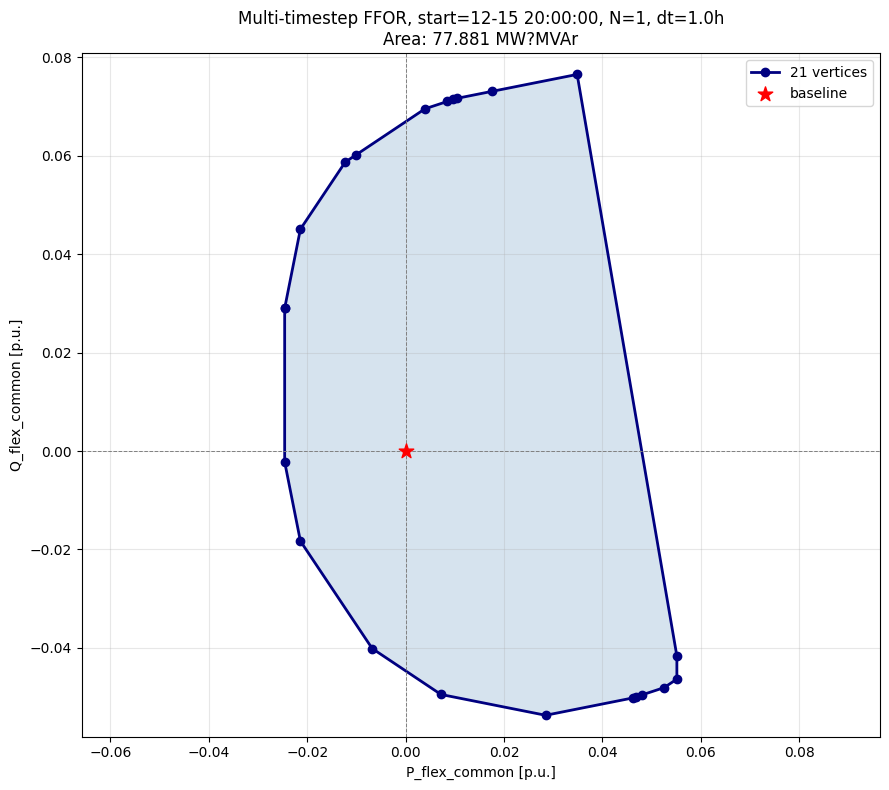

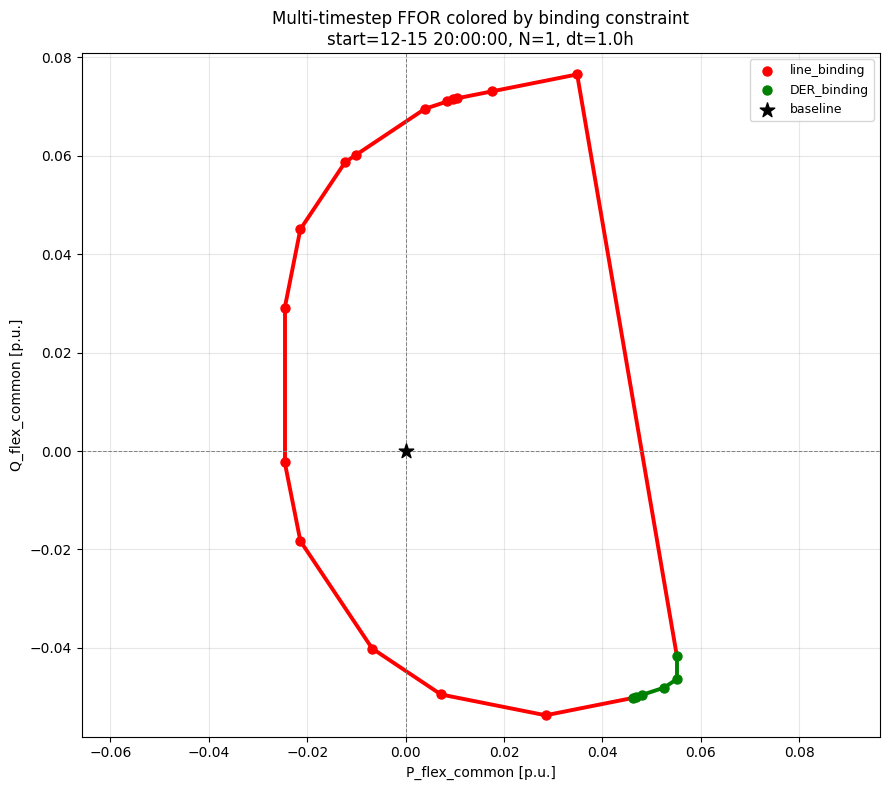

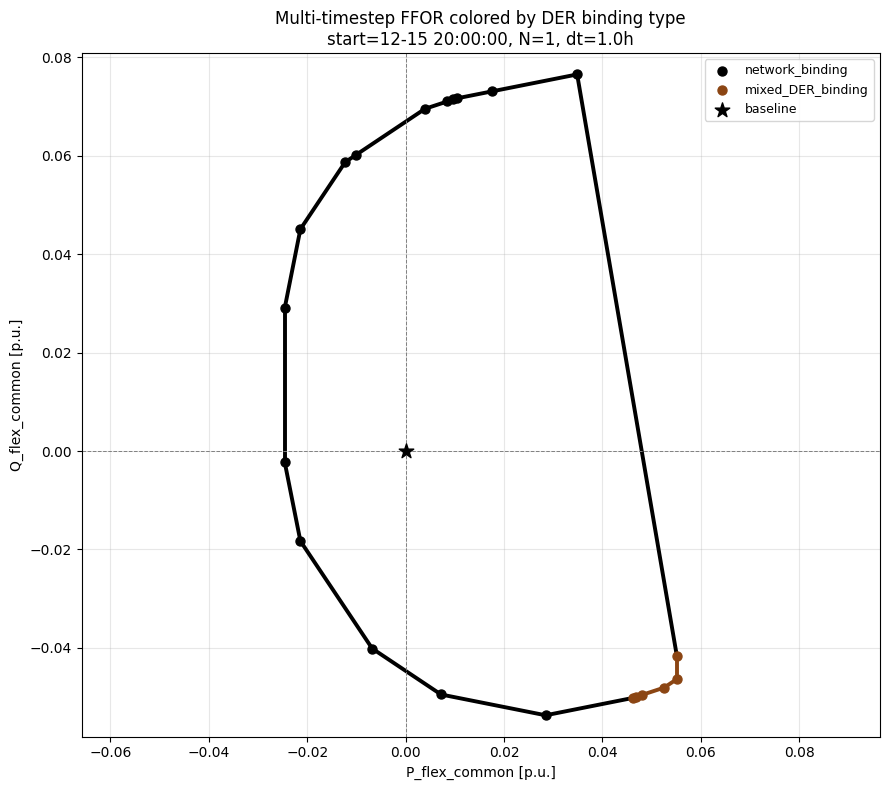

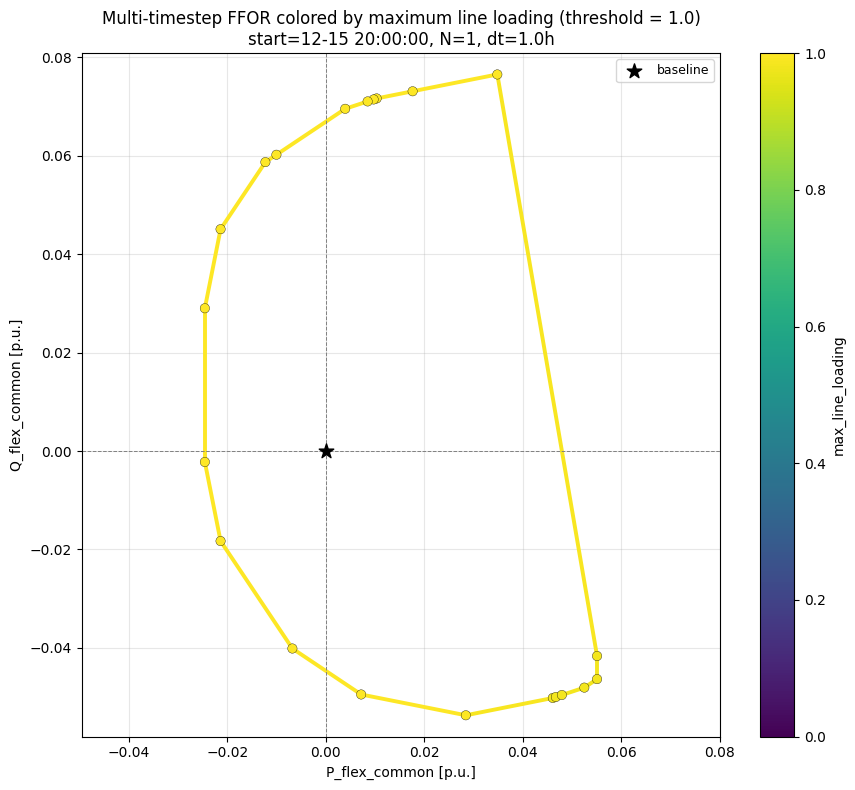

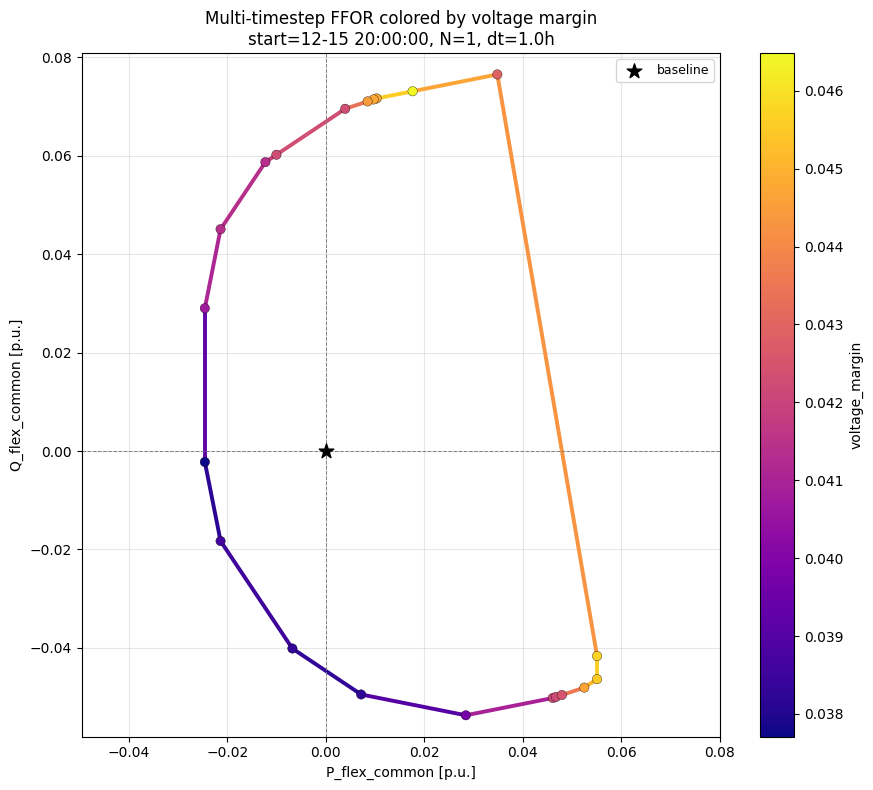

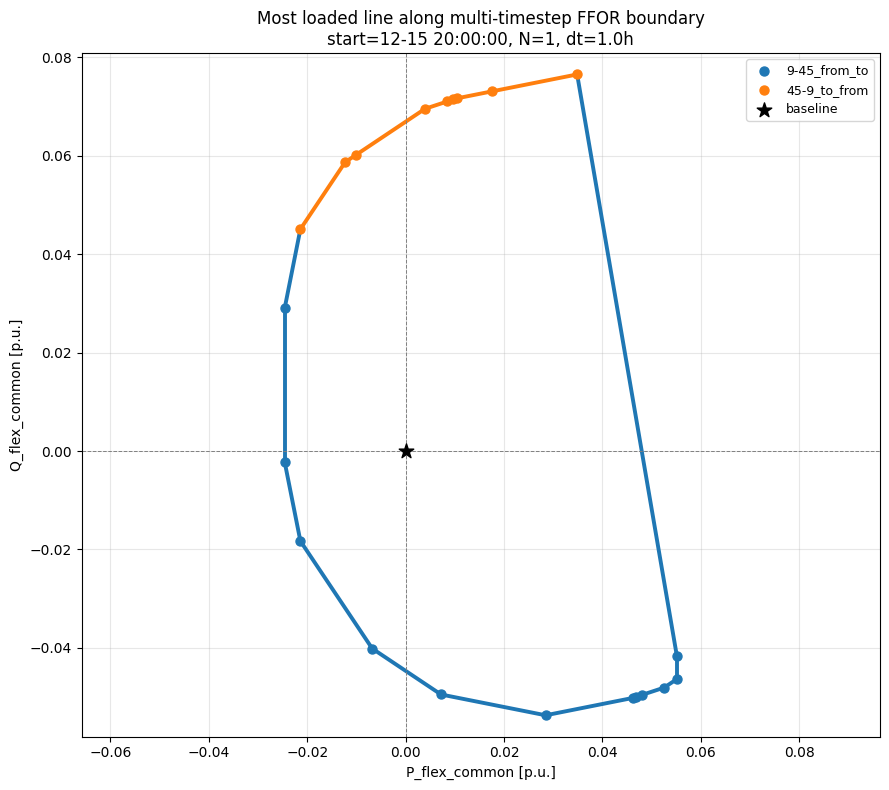

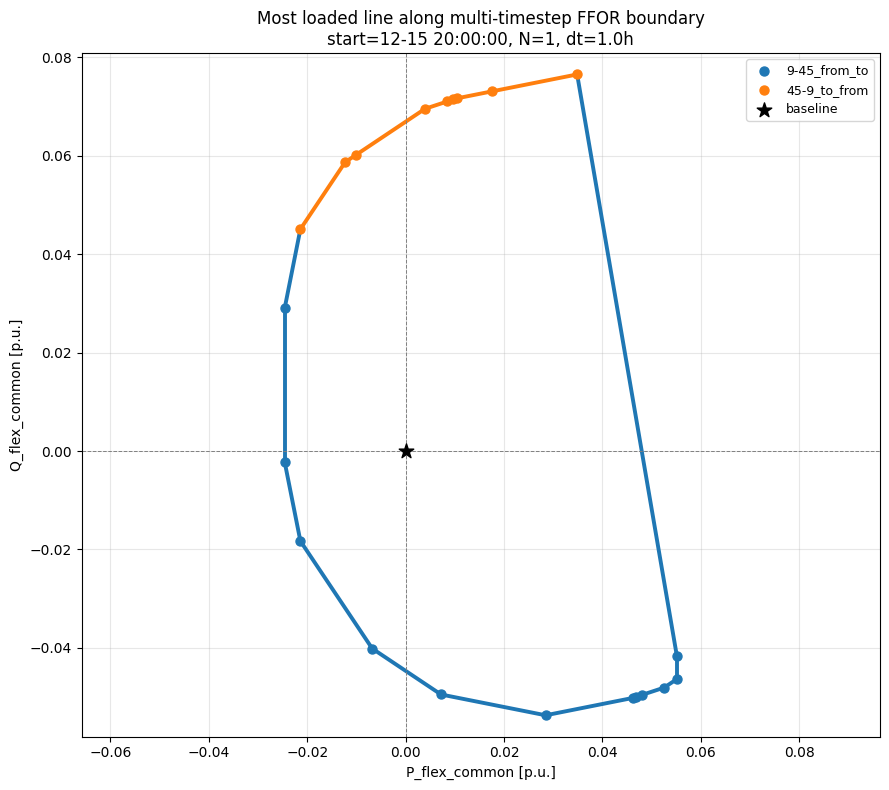

In [18]:
# === Multi-timestep FFOR plots ===
PLOT_TITLE_SUFFIX = f"start={START_TIMESTAMP}, N={N_TIMESTEPS}, dt={DT_H}h"
X_COL = "P_flex_pu"
Y_COL = "Q_flex_pu"


def _ordered_df(df):
    return df.sort_values("point_id").reset_index(drop=True)


def _segment_class(c0, c1, priority):
    if c0 == c1:
        return c0
    ranks = {name: rank for rank, name in enumerate(priority)}
    return min([c0, c1], key=lambda c: ranks.get(c, len(ranks)))


def plot_boundary_segments_categorical(df, class_column, color_map, output_path, title, class_order=None, priority=None):
    plot_df = _ordered_df(df)
    fig, ax = plt.subplots(figsize=(9, 8))
    n = len(plot_df)
    if n == 0:
        raise ValueError("Cannot plot an empty FFOR boundary dataframe")

    if class_order is None:
        class_order = [c for c in color_map if c in set(plot_df[class_column].dropna())]
        class_order += [c for c in plot_df[class_column].dropna().unique() if c not in class_order]
    if priority is None:
        priority = class_order

    for i in range(n):
        j = (i + 1) % n
        c0 = str(plot_df.loc[i, class_column])
        c1 = str(plot_df.loc[j, class_column])
        c = _segment_class(c0, c1, priority)
        ax.plot(
            [plot_df.loc[i, X_COL], plot_df.loc[j, X_COL]],
            [plot_df.loc[i, Y_COL], plot_df.loc[j, Y_COL]],
            color=color_map.get(c, "gray"),
            linewidth=2.8,
            solid_capstyle="round",
        )

    for class_name in class_order:
        mask = plot_df[class_column].astype(str).eq(str(class_name))
        if mask.any():
            ax.scatter(
                plot_df.loc[mask, X_COL], plot_df.loc[mask, Y_COL],
                s=42, color=color_map.get(class_name, "gray"), label=class_name, zorder=3,
            )

    ax.scatter([0.0], [0.0], s=120, color="black", marker="*", zorder=4, label="baseline")
    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.set_xlabel("P_flex_common [p.u.]")
    ax.set_ylabel("Q_flex_common [p.u.]")
    ax.set_title(f"{title}\n{PLOT_TITLE_SUFFIX}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)
    ax.set_aspect("equal", adjustable="datalim")
    plt.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    return fig


def plot_boundary_segments_continuous(df, value_column, output_path, title, cmap="viridis", vmin=None, vmax=None):
    plot_df = _ordered_df(df)
    fig, ax = plt.subplots(figsize=(9, 8))
    values = pd.to_numeric(plot_df[value_column], errors="coerce")
    if vmin is None and values.notna().any():
        vmin = float(values.min())
    if vmax is None and values.notna().any():
        vmax = float(values.max())
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cm = plt.get_cmap(cmap)

    n = len(plot_df)
    for i in range(n):
        j = (i + 1) % n
        vi = values.iloc[i]
        vj = values.iloc[j]
        segment_value = np.nanmean([vi, vj])
        color = cm(norm(segment_value)) if np.isfinite(segment_value) else "gray"
        ax.plot(
            [plot_df.loc[i, X_COL], plot_df.loc[j, X_COL]],
            [plot_df.loc[i, Y_COL], plot_df.loc[j, Y_COL]],
            color=color,
            linewidth=2.8,
            solid_capstyle="round",
        )

    scatter = ax.scatter(
        plot_df[X_COL], plot_df[Y_COL], c=values, cmap=cmap, norm=norm,
        s=46, edgecolor="black", linewidth=0.25, zorder=3,
    )
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label(value_column)
    ax.scatter([0.0], [0.0], s=120, color="black", marker="*", zorder=4, label="baseline")
    ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
    ax.set_xlabel("P_flex_common [p.u.]")
    ax.set_ylabel("Q_flex_common [p.u.]")
    ax.set_title(f"{title}\n{PLOT_TITLE_SUFFIX}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=9)
    ax.set_aspect("equal", adjustable="datalim")
    plt.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    return fig


# Plain boundary plot
fig, ax = plt.subplots(figsize=(9, 8))
plot_df = _ordered_df(df_boundary)
hull_xy = plot_df[[X_COL, Y_COL]].to_numpy(dtype=float)
hull_closed = np.vstack([hull_xy, hull_xy[0]])
ax.fill(hull_closed[:, 0], hull_closed[:, 1], alpha=0.22, color="steelblue")
ax.plot(hull_closed[:, 0], hull_closed[:, 1], "o-", color="navy", linewidth=2, markersize=6,
        label=f"{len(plot_df)} vertices")
ax.scatter([0.0], [0.0], s=120, color="red", marker="*", zorder=10, label="baseline")
ax.axhline(0, color="gray", linewidth=0.7, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.7, linestyle="--")
ax.set_xlabel("P_flex_common [p.u.]")
ax.set_ylabel("Q_flex_common [p.u.]")
ax.set_title(f"Multi-timestep FFOR, {PLOT_TITLE_SUFFIX}\nArea: {final_area_MVA2:.3f} MW?MVAr")
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=10)
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "ffor_multistep_boundary.png", dpi=150)
fig.savefig(OUTPUT_DIR / "ffor_multistep.png", dpi=150)
plt.show()

binding_color_map = {
    "line_binding": "red",
    "near_line_binding": "darkred",
    "voltage_binding": "blue",
    "near_voltage_binding": "lightblue",
    "DER_binding": "green",
    "mixed_network_binding": "purple",
    "not_identified": "gray",
}
binding_priority = [
    "mixed_network_binding",
    "line_binding",
    "voltage_binding",
    "DER_binding",
    "near_line_binding",
    "near_voltage_binding",
    "not_identified",
]
plot_boundary_segments_categorical(
    df_boundary,
    class_column="dominant_binding_class",
    color_map=binding_color_map,
    output_path=OUTPUT_DIR / "ffor_multistep_colored_by_binding_constraint.png",
    title="Multi-timestep FFOR colored by binding constraint",
    class_order=binding_priority,
    priority=binding_priority,
)

der_plot_df = df_boundary.copy()
der_plot_df["DER_plot_class"] = np.where(
    der_plot_df["dominant_binding_class"].eq("DER_binding"),
    der_plot_df["dominant_DER_binding_class"],
    np.where(der_plot_df["dominant_binding_class"].eq("not_identified"), "DER_not_identified", "network_binding"),
)
der_color_map = {
    "PV_binding": "orange",
    "HP_power_binding": "purple",
    "HP_temperature_binding": "magenta",
    "BESS_power_binding": "green",
    "BESS_SOC_binding": "brown",
    "mixed_DER_binding": "saddlebrown",
    "DER_not_identified": "gray",
    "network_binding": "black",
}
der_priority = [
    "network_binding",
    "mixed_DER_binding",
    "BESS_SOC_binding",
    "BESS_power_binding",
    "PV_binding",
    "HP_temperature_binding",
    "HP_power_binding",
    "DER_not_identified",
]
plot_boundary_segments_categorical(
    der_plot_df,
    class_column="DER_plot_class",
    color_map=der_color_map,
    output_path=OUTPUT_DIR / "ffor_multistep_colored_by_DER_binding.png",
    title="Multi-timestep FFOR colored by DER binding type",
    class_order=der_priority,
    priority=der_priority,
)

line_loading_values = pd.to_numeric(df_boundary["max_line_loading"], errors="coerce")
plot_boundary_segments_continuous(
    df_boundary,
    value_column="max_line_loading",
    output_path=OUTPUT_DIR / "ffor_multistep_colored_by_max_line_loading.png",
    title="Multi-timestep FFOR colored by maximum line loading (threshold = 1.0)",
    cmap="viridis",
    vmin=0.0 if line_loading_values.notna().any() else None,
    vmax=max(1.0, float(line_loading_values.max())) if line_loading_values.notna().any() else None,
)

voltage_margin_values = pd.to_numeric(df_boundary["voltage_margin"], errors="coerce")
plot_boundary_segments_continuous(
    df_boundary,
    value_column="voltage_margin",
    output_path=OUTPUT_DIR / "ffor_multistep_colored_by_voltage_margin.png",
    title="Multi-timestep FFOR colored by voltage margin",
    cmap="plasma",
    vmin=float(voltage_margin_values.min()) if voltage_margin_values.notna().any() else None,
    vmax=float(voltage_margin_values.max()) if voltage_margin_values.notna().any() else None,
)

most_loaded_counts = df_boundary["most_loaded_line"].fillna("not_identified").value_counts(dropna=False)
top_lines = list(most_loaded_counts.head(8).index)
most_loaded_df = df_boundary.copy()
most_loaded_df["most_loaded_line_plot_class"] = most_loaded_df["most_loaded_line"].fillna("not_identified")
most_loaded_df.loc[~most_loaded_df["most_loaded_line_plot_class"].isin(top_lines), "most_loaded_line_plot_class"] = "other"
line_classes = list(dict.fromkeys(top_lines + (["other"] if "other" in set(most_loaded_df["most_loaded_line_plot_class"]) else [])))
palette = list(plt.get_cmap("tab10").colors) + list(plt.get_cmap("tab20").colors)
line_color_map = {class_name: palette[i % len(palette)] for i, class_name in enumerate(line_classes)}
line_color_map.setdefault("not_identified", "gray")
line_color_map.setdefault("other", "black")
plot_boundary_segments_categorical(
    most_loaded_df,
    class_column="most_loaded_line_plot_class",
    color_map=line_color_map,
    output_path=OUTPUT_DIR / "ffor_multistep_colored_by_most_loaded_line.png",
    title="Most loaded line along multi-timestep FFOR boundary",
    class_order=line_classes,
    priority=line_classes,
)

In [19]:
# === Save CSV outputs and model summary ===
ffor_points.to_csv(OUTPUT_DIR / "ffor_boundary_points.csv", index=False)
df_boundary.to_csv(OUTPUT_DIR / "ffor_boundary_binding_classes.csv", index=False)
ffor_boundary_points_by_timestep.to_csv(OUTPUT_DIR / "ffor_boundary_points_by_timestep.csv", index=False)
df_diag_t.to_csv(OUTPUT_DIR / "ffor_boundary_diagnostics_by_timestep.csv", index=False)
if not line_flows_by_boundary_point.empty:
    line_flows_by_boundary_point.to_csv(OUTPUT_DIR / "line_flows_by_boundary_point.csv", index=False)

hull_df = df_boundary[["P_flex_pu", "Q_flex_pu", "P_flex_MW", "Q_flex_MVAr"]].copy()
hull_df.to_csv(OUTPUT_DIR / "ffor_hull_ordered.csv", index=False)
baseline_pf_df.to_csv(OUTPUT_DIR / "baseline_by_timestep.csv", index=False)
if "hp_assets_df" in globals() and not hp_assets_df.empty:
    hp_assets_df.to_csv(OUTPUT_DIR / "hp_assets_diagnostics.csv", index=False)

manifest = {
    "grid_name": GRID_NAME,
    "data_year": DATA_YEAR,
    "target_time": TARGET_TIME,
    "start_timestamp": START_TIMESTAMP,
    "N_TIMESTEPS": N_TIMESTEPS,
    "DT_H": DT_H,
    "horizon_hours": N_TIMESTEPS * DT_H,
    "timesteps": TIMESTEPS,
    "sbase_mva": SBASE_MVA,
    "n_pv_assets": len(pv_assets),
    "n_hp_assets": len(hp_assets),
    "hp_power_margin_factor": HP_POWER_MARGIN_FACTOR,
    "hp_max_model": "P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR",
    "n_bess_assets": len(bess_assets),
    "ev_modeled_as_fixed_load_only": True,
    "n_lp_variables": n_var,
    "n_equality_constraints": int(len(b_eq)),
    "n_inequality_constraints": int(len(b_ub)),
    "final_soc_constraint_enabled": ENFORCE_FINAL_SOC,
    "final_temperature_constraint_enabled": ENFORCE_FINAL_TEMPERATURE,
    "ffor_area_MW_MVAr": final_area_MVA2,
    "ffor_n_vertices": len(final_hull),
    "quickflex_iterations": iteration,
    "baseline_solve_mode": baseline_solve_mode,
}
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

model_summary_lines = [
    f"number of timesteps: {N_TIMESTEPS}",
    f"DT_H: {DT_H}",
    f"number of variables: {n_var}",
    f"number of equality constraints: {len(b_eq)}",
    f"number of inequality constraints: {len(b_ub)}",
    f"number of PV assets: {len(pv_assets)}",
    f"number of HP assets: {len(hp_assets)}",
    f"HP power margin factor: {HP_POWER_MARGIN_FACTOR}",
    "HP max model: P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR",
    f"number of BESS assets: {len(bess_assets)}",
    "EV modeled as fixed load only: True",
    "BESS efficiency is approximated as 100%.",
    "A single signed BESS active power variable is used.",
    "Positive BESS power denotes discharge; negative BESS power denotes charge.",
    "This avoids simultaneous charge/discharge while keeping the problem linear.",
    f"final SOC constraint enabled: {ENFORCE_FINAL_SOC}",
    f"final temperature constraint enabled: {ENFORCE_FINAL_TEMPERATURE}",
]
(OUTPUT_DIR / "model_summary.txt").write_text("\n".join(model_summary_lines) + "\n", encoding="utf-8")

print("Multi-timestep FFOR completed")
print("N_TIMESTEPS:", N_TIMESTEPS)
print("DT_H:", DT_H)
print("Start timestamp:", START_TIMESTAMP)
print("HP power margin factor:", HP_POWER_MARGIN_FACTOR)
print("HP max model: P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR")
print("P_flex range:", df_boundary["P_flex_pu"].min(), df_boundary["P_flex_pu"].max())
print("Q_flex range:", df_boundary["Q_flex_pu"].min(), df_boundary["Q_flex_pu"].max())
print("Dominant binding counts:")
print(df_boundary["dominant_binding_class"].value_counts(dropna=False))
print("Dominant DER binding counts:")
print(df_boundary["dominant_DER_binding_class"].value_counts(dropna=False))

print("BESS simultaneous charge/discharge check: not applicable with signed bess_p formulation.")

print("\nOutputs saved to:", OUTPUT_DIR)
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {f.name}")

Multi-timestep FFOR completed
N_TIMESTEPS: 1
DT_H: 1.0
Start timestamp: 12-15 20:00:00
HP power margin factor: 0.9
HP max model: P_HP_max = P_peak / HP_POWER_MARGIN_FACTOR
P_flex range: -0.02457589213353588 0.055115179939409675
Q_flex range: -0.05369010104319165 0.07652433779868449
Dominant binding counts:
dominant_binding_class
line_binding    15
DER_binding      6
Name: count, dtype: int64
Dominant DER binding counts:
dominant_DER_binding_class
mixed_DER_binding    21
Name: count, dtype: int64
BESS simultaneous charge/discharge check: not applicable with signed bess_p formulation.

Outputs saved to: outputs\ffor_multistep_20_0_2050_12-15_20-00-00_N1_dt1.0
  baseline_by_timestep.csv
  diagnostic_multistep.png
  ffor_boundary_binding_classes.csv
  ffor_boundary_diagnostics_by_timestep.csv
  ffor_boundary_points.csv
  ffor_boundary_points_by_timestep.csv
  ffor_hull_ordered.csv
  ffor_multistep.png
  ffor_multistep_boundary.png
  ffor_multistep_colored_by_binding_constraint.png
  ffor_m

## 10. Diagnostica: SoC e temperatura nel tempo

Per ogni punto della frontiera FFOR, visualizza l'evoluzione del SoC BESS e della temperatura interna HP lungo l'orizzonte. Le curve usano le soluzioni multi-timestep gia' calcolate per i vertici QuickFlex.

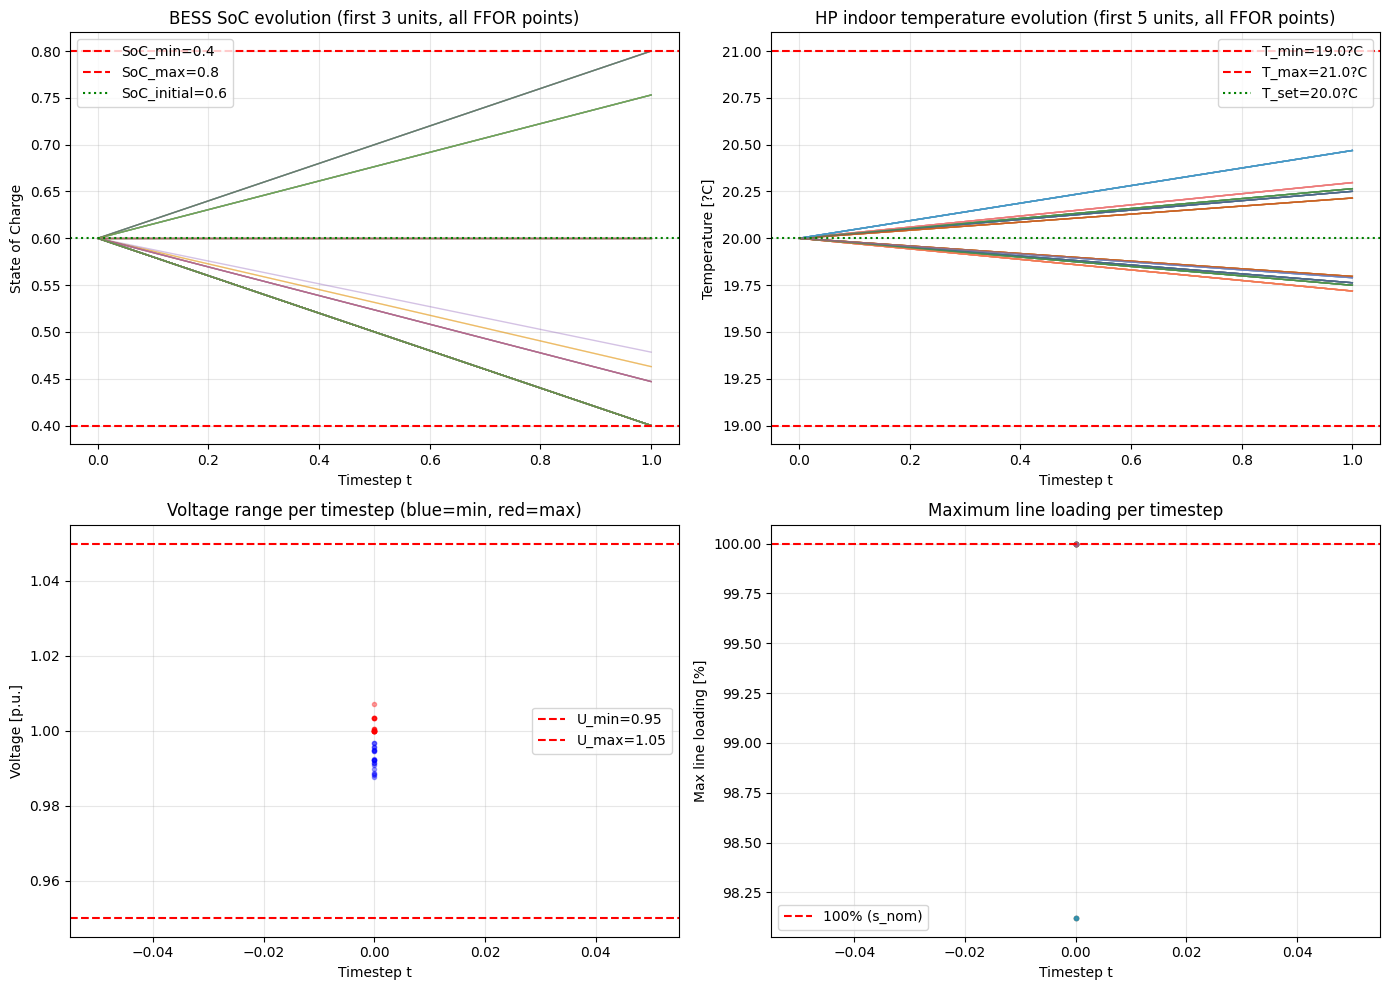

In [20]:
# Pick representative ordered boundary points
ffor_points_sorted = ffor_points.sort_values("point_angle_deg").reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- SoC evolution ---
ax = axes[0, 0]
for _, row in ffor_points_sorted.iterrows():
    info = ordered_boundary_infos[int(row["point_id"])]
    x = info["x"]
    for a in range(min(3, len(bess_assets))):
        soc_t = [x[bess_soc[(a, t)]] for t in range(N_TIMESTEPS + 1)]
        ax.plot(range(N_TIMESTEPS + 1), soc_t, alpha=0.4, linewidth=1)
ax.axhline(SOC_MIN, color="red", linestyle="--", label=f"SoC_min={SOC_MIN}")
ax.axhline(SOC_MAX, color="red", linestyle="--", label=f"SoC_max={SOC_MAX}")
ax.axhline(SOC_INITIAL, color="green", linestyle=":", label=f"SoC_initial={SOC_INITIAL}")
ax.set_xlabel("Timestep t")
ax.set_ylabel("State of Charge")
ax.set_title("BESS SoC evolution (first 3 units, all FFOR points)")
ax.legend(loc="best")
ax.grid(alpha=0.3)

# --- Temperature evolution ---
ax = axes[0, 1]
for _, row in ffor_points_sorted.iterrows():
    info = ordered_boundary_infos[int(row["point_id"])]
    x = info["x"]
    for a in range(min(5, len(hp_assets))):
        temp_t = [x[hp_temp[(a, t)]] for t in range(N_TIMESTEPS + 1)]
        ax.plot(range(N_TIMESTEPS + 1), temp_t, alpha=0.4, linewidth=1)
ax.axhline(T_MIN_C, color="red", linestyle="--", label=f"T_min={T_MIN_C}?C")
ax.axhline(T_MAX_C, color="red", linestyle="--", label=f"T_max={T_MAX_C}?C")
ax.axhline(T_SET_C, color="green", linestyle=":", label=f"T_set={T_SET_C}?C")
ax.set_xlabel("Timestep t")
ax.set_ylabel("Temperature [?C]")
ax.set_title("HP indoor temperature evolution (first 5 units, all FFOR points)")
ax.legend(loc="best")
ax.grid(alpha=0.3)

# --- Voltage range across timesteps for each FFOR vertex ---
ax = axes[1, 0]
for _, row in ffor_points_sorted.iterrows():
    point_id = int(row["point_id"])
    multi = df_diag_t[df_diag_t["point_id"].eq(point_id)].sort_values("timestep")
    if multi.empty:
        continue
    ax.plot(multi["timestep"], multi["V_min_pu"], color="blue", marker="o", markersize=3, linewidth=1, alpha=0.35)
    ax.plot(multi["timestep"], multi["V_max_pu"], color="red", marker="o", markersize=3, linewidth=1, alpha=0.35)
ax.axhline(0.95, color="red", linestyle="--", label="U_min=0.95")
ax.axhline(1.05, color="red", linestyle="--", label="U_max=1.05")
ax.set_xlabel("Timestep t")
ax.set_ylabel("Voltage [p.u.]")
ax.set_title("Voltage range per timestep (blue=min, red=max)")
ax.legend(loc="best")
ax.grid(alpha=0.3)

# --- Line loading max per timestep ---
ax = axes[1, 1]
for _, row in ffor_points_sorted.iterrows():
    point_id = int(row["point_id"])
    multi = df_diag_t[df_diag_t["point_id"].eq(point_id)].sort_values("timestep")
    if multi.empty:
        continue
    ax.plot(multi["timestep"], multi["max_line_loading"] * 100, marker="o", markersize=3, linewidth=1, alpha=0.5)
ax.axhline(100, color="red", linestyle="--", label="100% (s_nom)")
ax.set_xlabel("Timestep t")
ax.set_ylabel("Max line loading [%]")
ax.set_title("Maximum line loading per timestep")
ax.legend(loc="best")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "diagnostic_multistep.png", dpi=150)
plt.show()